In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time
import scipy

from scipy import linalg
from scipy.sparse.linalg import eigsh
from scipy.sparse.linalg import spsolve
from scipy.sparse import diags
from scipy.sparse import identity

In [2]:
def trig_sum(x,n):
    func_val = 0
    for i in range(0,n):
        func_val = func_val + (1/(i+1))*np.sin((i+1)*x)
        
    return func_val

def trig_sum_square(x,n):
    func_val = 0
    for i in range(0,n):
        func_val = func_val + (1+(-1)**i)*(1/(i+1))*np.sin((i+1)*x)
        
    return 2*func_val

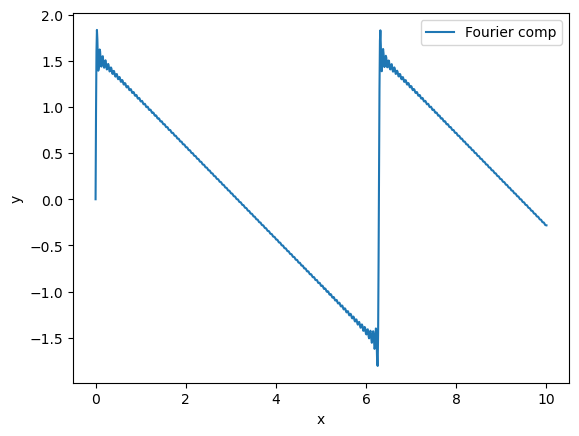

In [3]:
x = np.linspace(0,10,1000)
y = np.zeros(100)
plt.plot(x,trig_sum(x,100),label='Fourier comp')
plt.xlabel("x")
plt.ylabel("y")
plt.legend()

plt.show()

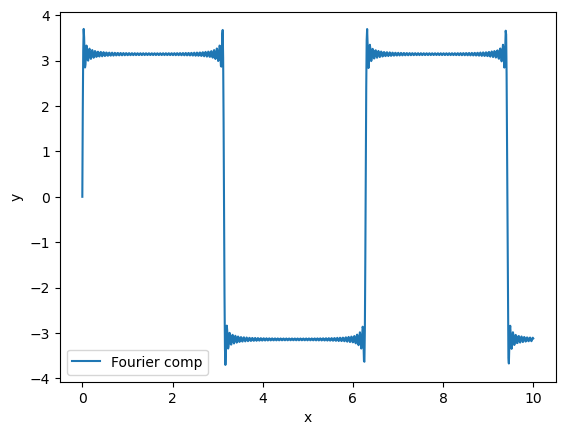

In [4]:
x = np.linspace(0,10,1000)
y = np.zeros(100)
plt.plot(x,trig_sum_square(x,100),label='Fourier comp')
plt.xlabel("x")
plt.ylabel("y")
plt.legend()

plt.show()

In [5]:
def rms(y):
    sum_val = 0
    for i in range(0,len(y)):
        sum_val = sum_val + y[i]**2

    sum_val = (sum_val)**0.5/len(y)
    return sum_val

test_a = np.arange(10)
print(len(test_a))
print(rms(test_a))

10
1.6881943016134133


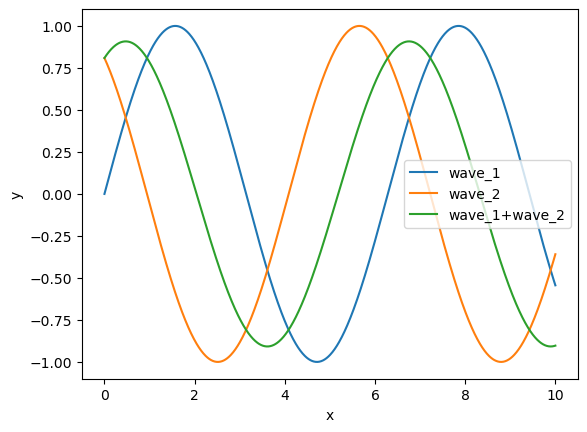

In [6]:
x = np.linspace(0,10,1000)
phase = 0.7*np.pi
wave_1 = np.sin(x)
wave_2 = np.sin(x+phase)

plt.plot(x, wave_1, label='wave_1')
plt.plot(x, wave_2, label='wave_2')
plt.plot(x, wave_1+wave_2, label='wave_1+wave_2')

plt.xlabel("x")
plt.ylabel("y")
plt.legend()

plt.show()

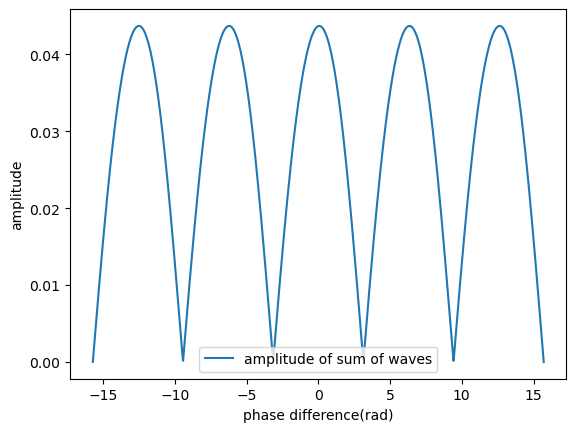

In [7]:
wave_1 = np.sin(x)
#wave_2 = np.sin(x+phase)
angle_res = 1000
angle_lst = np.linspace(-5*np.pi,5*np.pi,angle_res)
rms_wave_sum = np.zeros(angle_res)

for i in range(0,len(angle_lst)):
    rms_wave_sum[i] = rms(wave_1+np.sin(x+angle_lst[i]))

plt.plot(angle_lst, rms_wave_sum, label='amplitude of sum of waves')

plt.xlabel("phase difference(rad)")
plt.ylabel("amplitude")
plt.legend()

plt.show()

In [8]:
#beamline comp test
filename_with_ap = "nuSTORMBeamLine-Params-Full.csv"
filename_ori = "test.csv"

filein = open(filename_with_ap, "r")            # Open file for reading
inputd_with_ap = filein.readlines()

filein = open(filename_ori, "r")            # Open file for reading
inputd_ori = filein.readlines()

In [9]:
print(len(inputd_with_ap))
print(len(inputd_ori))
print(inputd_with_ap[1])
print(inputd_ori[5])
beam_with_ap_data = inputd_with_ap[1:]
beam_ori_data = inputd_ori[5:]

224
187
1,ProductionStraight,Drift,,Length,1.8,m,"d1"

1,ProductionStraight,Drift,,Length,1.8,m,"d1"



In [10]:
ap_count = 0
match_index_lst = []
for i in range(0,len(beam_with_ap_data)):
    if "Aperture" in beam_with_ap_data[i]:
        ap_count = ap_count + 1
    elif beam_with_ap_data[i] == beam_ori_data[i-ap_count]:
        #print(str(ori_data_index)+" th element same")
        match_index_lst.append(i-ap_count)
    else:
        print(str(i-ap_count)+" th element Unmatch : "+str(beam_ori_data[i-ap_count]))
        
print(match_index_lst)
print(len(match_index_lst))

13 th element Unmatch : 1,ProductionStraight,Fquad,,kq,0.350557,m-2,

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181]
181


In [8]:
np.random.random()

0.6140768177420445

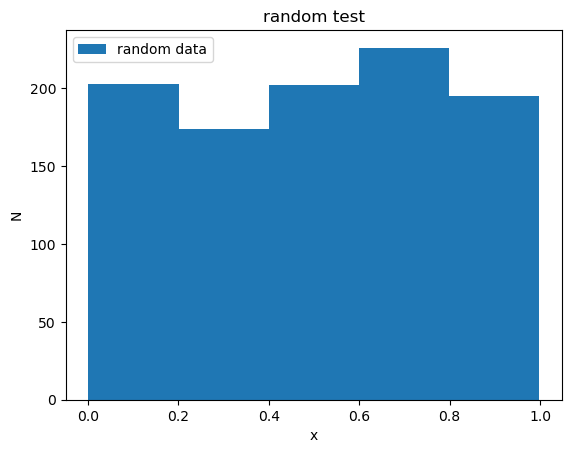

In [4]:
NBins = 5
random_num_lst = np.random.random(1000)
hist, bins, p = plt.hist(random_num_lst, bins=NBins, label='random data')

#plt.hist(bins[:-1], bins, weights=hist, label='random data') #original data
plt.title("random test")
plt.xlabel('x')
plt.ylabel('N')
plt.legend()
plt.show()

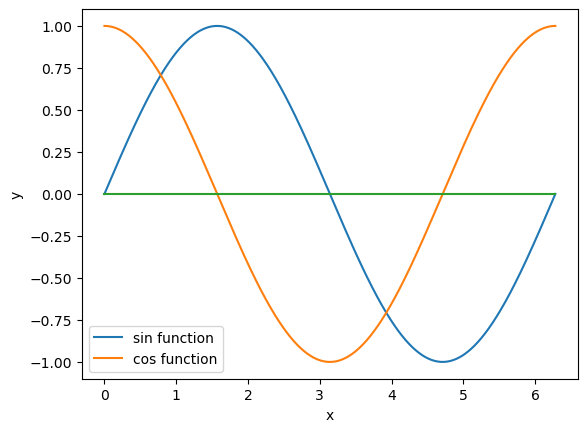

In [10]:
x = np.linspace(0,2*np.pi,1000)
y = np.zeros(1000)

plt.plot(x,np.sin(x),label='sin function')
plt.plot(x,np.cos(x),label='cos function')
plt.plot(x,y)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()

plt.show()

In [11]:
Lin_optics_file = open("Test4WC-Params-Flat.dat", "r")
read_lin_optics = Lin_optics_file.read(4)
print(read_lin_optics)

UnicodeDecodeError: 'charmap' codec can't decode byte 0x8d in position 318: character maps to <undefined>

In [8]:
def get_avg_p(E_lst, mass): 
    avg = 0
    for i in range(0,len(E_lst)):
        avg = avg + np.sqrt(E_lst[i]**2-mass**2)
        
    avg = avg/len(E_lst)
    return avg

def get_avg_Ek(E_lst, mass): 
    avg = 0
    for i in range(0,len(E_lst)):
        avg = avg + E_lst[i]-mass
        
    avg = avg/len(E_lst)
    return avg

def gamma_to_beta(gamma):
    return np.sqrt(1-1/gamma**2)

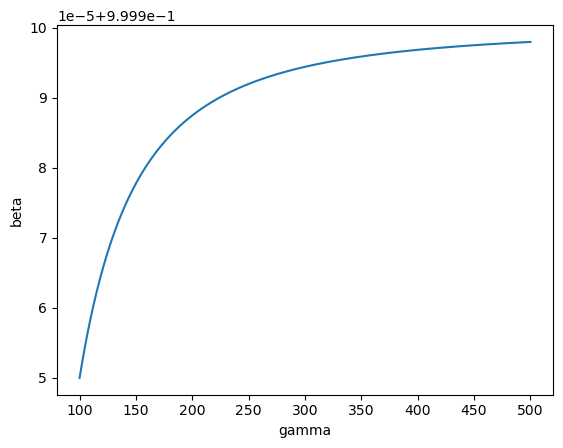

In [9]:
x = np.linspace(100,500,500)
y = gamma_to_beta(x)

plt.plot(x,y)
plt.xlabel("gamma")
plt.ylabel("beta")
plt.show()

In [10]:
get_avg_Ek([900,1000,1100],139.6)

860.4000000000001

In [11]:
np.sqrt(1000**2-139.6**2)

990.2079781540846

In [12]:
3000-139.57039

2860.42961

In [13]:
np.arctan(0.0305527633)*180/np.pi

1.7500000000807767

In [14]:
np.tan(1.75*np.pi/180)

0.030552763298588862

In [8]:
import random 

def getParabolic(p1):
    ran = random.random()
    a = np.array( [ 1., 0., (-3.*p1*p1), (2.*p1*p1*p1*(2.*ran - 1.)) ] )
    r = np.roots(a)
    isol = 0
    for ri in r:
        if not isinstance(ri, complex):
            if ri >= -p1:
                if ri <= p1:
                    isol += 1
                    p = ri
    if isol != 1:
        raise Exception("Simulation.getParabolic; p multiply defined")

    return p


In [9]:
getParabolic(3)

-1.0444737116106027

In [10]:
np.sqrt(899/900)

0.9994442900376633

In [11]:
for i in range(0,3):
    for j in range(0,3):
        if j>i:
            break
        print("i : "+str(i)+", j : "+str(j))

i : 0, j : 0
i : 1, j : 0
i : 1, j : 1
i : 2, j : 0
i : 2, j : 1
i : 2, j : 2


In [12]:
scipy.constants.c

299792458.0

In [9]:
s_lst_ap = [0.0, 1.8, 2.8, 2.8, 3.05, 4.05, 4.8, 5.8, 5.8, 7.8, 8.8, 8.8, 10.8, 11.8, 11.8, 12.0, 13.0, 13.8, 15.8, 16.1, 
            17.1, 17.1, 18.5, 19.5, 20.0, 21.0, 21.0, 23.9, 24.9, 24.9, 25.2, 27.2, 27.3, 28.3, 29.2, 30.2, 30.2, 31.087, 
            32.087, 32.087, 32.587, 33.587, 34.087, 36.587, 37.06120000000001, 37.76910000000001, 37.76910000000001, 
            38.23000000000001, 38.84920000000001, 38.84920000000001, 39.34920000000001, 40.34920000000001, 42.38860000000001, 
            42.94140000000001, 42.94140000000001, 45.24960000000001, 46.50090000000001, 46.50090000000001, 46.91040000000001, 
            49.41040000000001, 49.81040000000001, 50.39500000000001, 50.39500000000001, 51.49500000000001, 53.99500000000001,
            56.56800000000001, 57.56800000000001, 58.06800000000001, 58.56800000000001, 58.56800000000001, 58.768000000000015, 
            60.97718129426866, 61.17059629426866, 62.07064629426866, 62.27069629426866, 63.27069629426866, 63.27069629426866, 
            63.47074629426866, 64.37079629426866, 64.56421129426866, 66.7733925885373, 66.97339258853731, 67.47339258853731, 
            67.47339258853731, 81.8863925885373, 82.8863925885373, 83.8863925885373, 84.9863925885373, 84.9863925885373, 
            85.1863925885373, 86.2863925885373, 86.2863925885373, 86.80639258853729, 87.90639258853729, 87.90639258853729, 
            88.10639258853729, 89.20639258853728, 89.20639258853728, 101.54639258853729, 111.88639258853729, 112.88639258853729,
            113.88639258853729, 114.98639258853729, 114.98639258853729, 115.18639258853729, 116.28639258853728, 
            116.28639258853728, 116.80639258853728, 117.90639258853727, 117.90639258853727, 118.10639258853728, 
            119.20639258853727, 119.20639258853727, 131.54639258853726, 141.88639258853726, 142.88639258853726, 
            143.88639258853726, 144.98639258853726, 144.98639258853726, 145.18639258853725, 146.28639258853724, 
            146.28639258853724, 146.80639258853725, 147.90639258853724, 147.90639258853724, 148.10639258853723, 
            149.20639258853723, 149.20639258853723, 161.54639258853723, 171.88639258853723, 172.88639258853723, 
            173.88639258853723, 174.98639258853723, 174.98639258853723, 175.18639258853722, 176.2863925885372, 
            176.2863925885372, 176.80639258853722, 177.90639258853722, 177.90639258853722, 178.1063925885372, 
            179.2063925885372, 179.2063925885372, 191.5463925885372, 201.8863925885372, 202.8863925885372, 
            203.8863925885372, 204.9863925885372, 204.9863925885372, 205.1863925885372, 206.28639258853718, 
            206.28639258853718, 206.8063925885372, 207.9063925885372, 207.9063925885372, 208.10639258853718, 
            209.20639258853717, 209.20639258853717, 221.54639258853717, 231.88639258853718, 232.88639258853718,
            233.88639258853718, 234.98639258853717, 234.98639258853717, 235.18639258853716, 236.28639258853715, 
            236.28639258853715, 236.80639258853716, 237.90639258853716, 237.90639258853716, 238.10639258853715, 
            239.20639258853714, 239.20639258853714, 251.54639258853715]

print(len(s_lst_ap))

174


In [10]:
133 : Drift : Pos = [-1.57495250e+00  1.92223219e-16  2.39200559e+02] dr = [0. 0. 0.] dv = [0. 0. 0.]; length = 12.34
174 : Drift : Pos = [-1.57495250e+00  1.92223219e-16  2.39200559e+02] dr = [0. 0. 0.] dv = [0. 0. 0.]; length = 12.34

SyntaxError: illegal target for annotation (1296738112.py, line 1)

In [11]:
ap_lst = []
for i in range(0,len(s_lst_ap)-1):
    if (s_lst_ap[i+1]-s_lst_ap[i])/s_lst_ap[i+1]<0.000001:
        ap_lst.append(i)
        print(str(i)+" th element is Aperture")
        
print(str(len(ap_lst))+" Aperture in beamline")

2 th element is Aperture
7 th element is Aperture
10 th element is Aperture
13 th element is Aperture
20 th element is Aperture
25 th element is Aperture
28 th element is Aperture
35 th element is Aperture
38 th element is Aperture
45 th element is Aperture
48 th element is Aperture
53 th element is Aperture
56 th element is Aperture
61 th element is Aperture
68 th element is Aperture
75 th element is Aperture
82 th element is Aperture
87 th element is Aperture
90 th element is Aperture
93 th element is Aperture
96 th element is Aperture
102 th element is Aperture
105 th element is Aperture
108 th element is Aperture
111 th element is Aperture
117 th element is Aperture
120 th element is Aperture
123 th element is Aperture
126 th element is Aperture
132 th element is Aperture
135 th element is Aperture
138 th element is Aperture
141 th element is Aperture
147 th element is Aperture
150 th element is Aperture
153 th element is Aperture
156 th element is Aperture
162 th element is Apertu

In [13]:
#KS_prob_xy_binned_lst -
KS_prob_xy_binned_lst_fixed_quad = [1.0, 1.0, 0.9999998018931008, 0.9999990529626812, 0.9997118045517042, 0.995626709623168, 0.925973095884866, 0.5953966937497587, 0.376515823691505, 
 0.1501568419731943, 0.04620134398269737, 0.034117955100261325, 0.010030573340470837, 0.002470655949514466, 2.393490671940247e-09, 7.13486233474997e-15, 
 3.4222473475505115e-25, 1.121949916025005e-36, 0.0, 0.0, 0.0, 0.0, 1.0769966696696255e-24, 1.4755875893656212e-23, 1.0588416351256978e-17, 
 8.78581311659e-18, 1.8261672664299537e-17, 1.0055055868666628e-16, 1.6450421865065524e-16, 8.330087391841849e-16, 5.436584590005567e-17, 
 3.865136380408516, 3.3011572832881253e-16, 3.0329722637908503e-16, 5.8309203820601356e-21, 5.599321301313556e-23, 9.647894568353778e-27, 
 5.104977150591043e-30, 00.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 
 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 00.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 00.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 
 0.0, 0.0, 1.4697041889981763e-37, 9.36478705868e-38, 2.1821482416764445e-36, 2.8859785938387587e-37, 3.9042481178730696e-38, 4.972893949601694e-39, 
 0.0, 2.9229278392774323e-39, 2.30571915105e-39, 5.785232566395197e-38, 0.0]


#7.13486233474997e-15 is guessed since it didn't print corrently in the console


KS_prob_xy_binned_lst_before_fixed_quad = [1.0, 1.0, 1.0, 0.9999999999984927, 0.9999840586907669, 0.9988736679819016, 0.9512539348000382, 
 0.6478137663451896, 0.4082856724774093, 0.1452893054293905, 6.996404448150517e-05, 4.284515580563652e-09, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 
 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 
 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0988443687632605e-35, 6.050996519801407e-36, 1.3042318140798794e-34, 2.834776653029126e-35,
 9.029496102016297e-36, 5.4744550925527754e-36, 6.660122372866689e-38, 3.396161208224964e-37, 7.28237002671851e-38, 1.0226481463012957e-36, 0.0]



In [12]:

s_lst = np.array([0.0, 1.8, 2.8, 3.05, 4.05, 4.8, 5.8, 7.8, 8.8, 10.8, 11.8, 12.0, 13.0, 13.8, 15.8, 16.099998984608757, 
         17.099998527682743, 18.49999700459603, 19.499994872274634, 19.99999334918792, 20.999992587644567, 23.899991064557852, 
         24.89998664760639, 25.199985124519678, 27.199984667593665, 27.299977559858664, 28.29997695062444, 29.199970858282228, 
         30.19996537517424, 31.08695928283203, 32.08695387892449, 32.58694778658228, 33.58694474041118, 34.086938648068966, 
         36.58693560189786, 37.06111199405693, 37.76900571004424, 38.22989632908139, 38.849090221317894, 39.34908201579141, 
         40.34907538988178, 42.38846213806253, 42.94123511230234, 45.24942778669666, 46.500697198847455, 46.91018061684602, 
         49.410175190226035, 49.810096430599714, 50.394674667370936, 51.49464286041207, 53.99458301153292, 56.56750459569854,
         57.56747102502425, 58.067457977735366, 58.56745145409092, 58.76744493044648, 60.97662361525735, 61.16998923579104, 
         62.070032815040314, 62.270058879262024, 63.27005477851932, 63.470084279930404, 64.3701301791877, 64.56353130157193, 
         66.7727104979586, 66.97266749376149, 67.47266156858034, 81.88564675562746, 82.88521975744808, 83.88519013154234, 
         84.9851605056366, 85.18512791714029, 86.28512199195913, 86.80508940346282, 87.90507399799183, 88.10504140949553, 
         89.20503548431437, 101.54500289581806, 111.88463731214128, 112.88433098027596, 113.88430135437022, 114.98427172846448, 
         115.18423913996817, 116.28423321478701, 116.8042006262907, 117.90418522081971, 118.1041526323234, 119.20414670714224, 
         131.54411411864592, 141.88374853496916, 142.88344220310384, 143.8834125771981, 144.98338295129236, 145.18335036279603, 
         146.2833444376149, 146.8033118491186, 147.90329644364758, 148.10326385515125, 149.2032579299701, 161.5432253414738, 
         171.882859757797, 172.8825534259317, 173.88252380002595, 174.9824941741202, 175.18246158562388, 176.28245566044274, 
         176.80242307194644, 177.90240766647543, 178.1023750779791, 179.20236915279796, 191.54233656430165, 201.88197098062486, 
         202.88166464875954, 203.8816350228538, 204.98160539694805, 205.18157280845173, 206.28156688327059, 206.80153429477429, 
         207.90151888930328, 208.10148630080695, 209.2014803756258, 221.5414477871295, 231.8810822034527, 232.8807758715874, 
         233.88074624568165, 234.9807166197759, 235.18068403127958, 236.28067810609843, 236.80064551760213, 237.90063011213113, 
         238.1005975236348, 239.20059159845366, 251.54055900995735])


N_lst_7GeV_low_stat = np.array([10000., 9962., 9931., 9921., 9888., 9869., 9848., 9791., 9764., 9708.,
  9682., 9680., 9655., 9633., 9584., 9573., 9549., 9512., 9492., 9482.,
  9464., 9404., 9380., 9377., 9334., 9332., 9304., 9284., 9265., 9247.,
  9217., 9213., 9187., 9175., 9117., 9109., 9083., 9069., 9053., 9041.,
  9016., 8967., 8952., 8898., 8870., 8860., 8799., 8788., 8777., 8753.,
  8697., 8638., 8614., 8606., 8591., 8588., 8546., 8541., 8521., 8514.,
  8486., 8484., 8464., 8460., 8417., 8416., 8405., 8096., 8071., 8047.,
  8029., 8027., 8002., 7989., 7968., 7965., 7946., 7695., 7497., 7478.,
  7457., 7431., 7427., 7404., 7397., 7380., 7378., 7359., 7130., 6934.,
  6918., 6904., 6878., 6871., 6849., 6840., 6823., 6821., 6805., 6629.,
  6449., 6432., 6416., 6395., 6394., 6382., 6369., 6354., 6351., 6340.,
  6144., 5987., 5970., 5952., 5938., 5936., 5919., 5912., 5903., 5900.,
  5883., 5707., 5565., 5549., 5534., 5520., 5518., 5506., 5499., 5487.,
  5486., 5472., 5305.,    0.,    0.])

N_lst_7GeV = np.array([67000.,66719.,66544.,66513.,66320.,66180.,66030.,65685.,65531.,65201.,
 65048.,65026.,64865.,64726.,64410.,64363.,64204.,63961.,63790.,63701.,
 63518.,63068.,62929.,62890.,62589.,62568.,62406.,62259.,62105.,61976.,
 61812.,61733.,61576.,61494.,61093.,61015.,60912.,60838.,60737.,60653.,
 60492.,60202.,60112.,59756.,59578.,59519.,59155.,59094.,58996.,58841.,
 58476.,58060.,57921.,57851.,57797.,57768.,57454.,57418.,57282.,57244.,
 57064.,57030.,56897.,56866.,56563.,56536.,56482.,54502.,54370.,54223.,
 54065.,54046.,53895.,53830.,53667.,53640.,53480.,51908.,50605.,50467.,
 50359.,50235.,50208.,50077.,50016.,49895.,49875.,49739.,48264.,47027.,
 46901.,46773.,46618.,46599.,46482.,46411.,46289.,46270.,46150.,44736.,
 43604.,43495.,43379.,43255.,43222.,43104.,43056.,42948.,42930.,42824.,
 41500.,40397.,40314.,40207.,40104.,40080.,39969.,39927.,39806.,39786.,
 39678.,38442.,37465.,37380.,37282.,37165.,37149.,37052.,37008.,36914.,
 36892.,36797.,35673.,    0.,    0.])
"""
N_lst_7GeV_ap = np.array([67010.,66678.,66531.,66531.,66499.,66327.,66190.,66015.,66015.,65674.,
 65512.,65512.,65216.,65047.,65047.,65013.,64822.,64712.,64417.,64360.,
 64186.,64186.,63943.,63813.,63732.,63589.,63589.,63090.,62947.,62947.,
 62901.,62630.,62616.,62483.,62345.,62193.,62180.,62055.,61897.,61897.,
 61826.,61655.,61580.,61182.,61107.,60996.,60996.,60920.,60830.,60830.,
 60769.,60606.,60334.,60261.,60261.,59929.,59757.,59721.,59655.,59261.,
 59214.,59129.,58584.,58434.,58059.,57658.,57522.,57427.,57360.,57290.,
 57260.,56912.,56877.,56753.,56653.,56460.,53747.,53725.,53610.,53584.,
 53278.,53248.,53189.,52928.,51068.,50929.,50813.,50665.,47775.,47753.,
 47620.,46970.,46920.,46788.,46753.,46726.,46601.,46237.,44889.,43714.,
 43615.,43498.,43379.,42370.,42347.,42227.,41816.,41751.,41651.,41649.,
 41634.,41518.,41491.,40194.,39116.,39023.,38921.,38820.,38088.,38069.,
 37963.,37713.,37653.,37548.,37548.,37525.,37414.,37404.,36224.,35265.,
 35174.,35090.,35005.,35004.,34977.,34887.,34850.,34791.,34705.,34705.,
 34691.,34584.,34582.,33569.,32768.,32691.,32593.,32519.,32515.,32492.,
 32393.,32335.,32281.,32200.,32200.,32190.,32107.,32074.,31105.,30319.,
 30239.,30155.,30062.,30059.,30043.,29958.,29928.,29889.,29798.,29798.,
 29789.,29705.,29695.,28789.,    0.])
"""
N_lst_7GeV_ap = np.array([67010.,66719.,66543.,66543.,66480.,66345.,66214.,66031.,66031.,65695.,
 65526.,65526.,65225.,65052.,65052.,65011.,64863.,64730.,64414.,64371.,
 64219.,64219.,64003.,63856.,63765.,63611.,63611.,63158.,63003.,63003.,
 62962.,62640.,62627.,62485.,62331.,62182.,62182.,62049.,61891.,61891.,
 61824.,61668.,61592.,61194.,61115.,61009.,61009.,60933.,60844.,60844.,
 60769.,60591.,60302.,60219.,60219.,59876.,59676.,59676.,59623.,59270.,
 59204.,59114.,59050.,58888.,58501.,58151.,58011.,57931.,57850.,57846.,
 57815.,57508.,57482.,57368.,57328.,57158.,55611.,55581.,55447.,55425.,
 55139.,55118.,55050.,54997.,53015.,52865.,52731.,52579.,50253.,50233.,
 50095.,49673.,49607.,49470.,49336.,49310.,49212.,48855.,47322.,46172.,
 46065.,45930.,45796.,45305.,45288.,45175.,45084.,45021.,44907.,44907.,
 44885.,44762.,44724.,43322.,42211.,42088.,41977.,41872.,41853.,41821.,
 41707.,41623.,41573.,41462.,41462.,41429.,41316.,41315.,40059.,39035.,
 38936.,38850.,38751.,38607.,38588.,38482.,38355.,38313.,38220.,38218.,
 38198.,38079.,38052.,36866.,35974.,35881.,35768.,35671.,35628.,35609.,
 35508.,35437.,35392.,35281.,35279.,35265.,35163.,35093.,34054.,33205.,
 33125.,33041.,32950.,32946.,32926.,32834.,32832.,32790.,32708.,32708.,
 32691.,32594.,32594.,31587.,    0.])

N_lst_6GeV = np.array([72900.,72520.,72295.,72251.,72034.,71871.,71668.,71227.,71005.,70572.,
 70371.,70320.,70100.,69944.,69543.,69490.,69278.,69001.,68803.,68688.,
 68492.,67889.,67687.,67636.,67259.,67240.,67017.,66840.,66660.,66477.,
 66269.,66169.,65953.,65854.,65319.,65230.,65096.,64994.,64897.,64790.,
 64621.,64217.,64119.,63677.,63428.,63341.,62860.,62786.,62670.,62450.,
 61943.,61496.,61320.,61231.,61152.,61116.,60744.,60711.,60541.,60500.,
 60329.,60286.,60136.,60089.,59701.,59666.,59568.,57146.,56986.,56848.,
 56657.,56617.,56433.,56349.,56161.,56134.,55945.,53904.,52247.,52102.,
 51933.,51765.,51734.,51560.,51493.,51328.,51298.,51122.,49275.,47793.,
 47653.,47524.,47382.,47345.,47198.,47132.,46973.,46946.,46773.,45077.,
 43712.,43582.,43471.,43336.,43306.,43159.,43088.,42957.,42930.,42791.,
 41261.,39971.,39851.,39715.,39591.,39546.,39426.,39362.,39227.,39214.,
 39083.,37662.,36512.,36424.,36311.,36187.,36162.,36042.,35986.,35861.,
 35846.,35728.,34447.,    0.,    0.])

N_lst_6GeV_ap = np.array([72905.,72505.,72269.,72269.,72219.,72001.,71839.,71618.,71618.,71182.,
 70969.,70969.,70514.,70314.,70314.,70269.,70084.,69914.,69527.,69463.,
 69258.,69258.,68964.,68756.,68673.,68447.,68447.,67859.,67659.,67659.,
 67597.,67226.,67218.,66992.,66779.,66569.,66569.,66390.,66180.,66180.,
 66081.,65894.,65786.,65268.,65185.,65028.,65028.,64929.,64826.,64826.,
 64720.,64508.,64125.,64007.,64007.,63571.,63297.,63297.,63220.,62748.,
 62676.,62557.,62544.,62353.,61937.,61448.,61260.,61169.,61085.,61085.,
 61041.,60637.,60594.,60417.,60375.,60183.,58955.,58921.,58785.,58752.,
 58344.,58310.,58231.,58208.,55693.,55549.,55387.,55229.,53429.,53395.,
 53223.,52852.,52769.,52605.,52493.,52459.,52283.,52008.,50182.,48696.,
 48550.,48390.,48246.,47827.,47796.,47641.,47575.,47495.,47348.,47348.,
 47328.,47150.,47110.,45440.,43978.,43846.,43717.,43562.,43553.,43528.,
 43364.,43328.,43273.,43138.,43138.,43111.,42966.,42966.,41414.,40120.,
 39994.,39876.,39740.,39615.,39596.,39467.,39363.,39309.,39167.,39164.,
 39136.,39005.,38988.,37606.,36447.,36339.,36238.,36142.,36097.,36077.,
 35971.,35924.,35868.,35762.,35756.,35731.,35602.,35562.,34299.,33198.,
 33108.,33022.,32931.,32928.,32908.,32795.,32795.,32748.,32656.,32656.,
 32644.,32528.,32526.,31379.,    0.])

N_lst_5GeV = np.array([74434.,73921.,73633.,73559.,73306.,73099.,72825.,72294.,72042.,71530.,
 71289.,71240.,70979.,70760.,70273.,70194.,69905.,69554.,69296.,69162.,
 68895.,68177.,67934.,67866.,67371.,67347.,67133.,66932.,66678.,66478.,
 66210.,66079.,65871.,65771.,65155.,65039.,64888.,64786.,64637.,64532.,
 64290.,63837.,63720.,63202.,62892.,62788.,62252.,62165.,62031.,61794.,
 61246.,60699.,60487.,60380.,60256.,60221.,59736.,59693.,59479.,59437.,
 59228.,59191.,59031.,58996.,58488.,58449.,58351.,55465.,55268.,55065.,
 54856.,54814.,54584.,54482.,54269.,54227.,53991.,51593.,49663.,49488.,
 49331.,49139.,49113.,48899.,48813.,48647.,48607.,48411.,46289.,44592.,
 44449.,44276.,44103.,44079.,43923.,43860.,43699.,43665.,43469.,41611.,
 40067.,39927.,39774.,39622.,39597.,39450.,39383.,39240.,39210.,39052.,
 37366.,36054.,35928.,35798.,35658.,35633.,35507.,35435.,35288.,35273.,
 35130.,33607.,32405.,32296.,32190.,32052.,32029.,31876.,31826.,31692.,
 31664.,31541.,30209.,    0.,    0.])
"""
N_lst_5GeV_ap = np.array([74434.,73956.,73703.,73703.,73628.,73350.,73154.,72867.,72867.,72337.,
 72052.,72052.,71509.,71262.,71262.,71213.,70910.,70699.,70213.,70136.,
 69897.,69897.,69547.,69298.,69183.,68951.,68951.,68285.,68043.,68043.,
 67966.,67457.,67432.,67177.,66975.,66762.,66762.,66554.,66281.,66281.,
 66173.,65959.,65834.,65292.,65189.,65049.,65049.,64936.,64770.,64770.,
 64676.,64455.,63994.,63866.,63866.,63312.,63034.,63034.,62939.,62361.,
 62266.,62138.,61952.,61706.,61182.,60644.,60408.,60287.,60180.,60172.,
 60138.,59650.,59598.,59398.,59340.,59071.,57288.,57249.,57047.,57018.,
 56535.,56493.,56397.,56271.,53391.,53197.,53026.,52822.,50786.,50752.,
 50556.,49979.,49900.,49718.,49693.,49659.,49482.,49121.,47054.,45356.,
 45209.,45051.,44868.,44255.,44222.,44031.,43724.,43653.,43481.,43476.,
 43443.,43266.,43251.,41386.,39925.,39790.,39654.,39507.,38860.,38832.,
 38669.,38432.,38334.,38174.,38174.,38147.,37996.,37984.,36353.,35044.,
 34938.,34836.,34710.,34709.,34681.,34538.,34507.,34435.,34305.,34305.,
 34281.,34143.,34141.,32678.,31434.,31306.,31195.,31073.,31069.,31044.,
 30903.,30862.,30815.,30688.,30688.,30661.,30522.,30495.,29179.,28127.,
 28031.,27949.,27842.,27839.,27812.,27711.,27690.,27657.,27528.,27528.,
 27506.,27408.,27401.,26180.,    0.])
"""
N_lst_5GeV_ap = np.array([74434.,73960.,73707.,73707.,73644.,73368.,73168.,72916.,72916.,72430.,
 72193.,72193.,71698.,71447.,71447.,71389.,71110.,70922.,70401.,70322.,
 70038.,70038.,69664.,69404.,69292.,69016.,69016.,68323.,68067.,68067.,
 67997.,67521.,67495.,67249.,67059.,66819.,66819.,66594.,66341.,66341.,
 66228.,65983.,65870.,65287.,65180.,65008.,65008.,64902.,64758.,64758.,
 64649.,64401.,63886.,63755.,63755.,63210.,62905.,62905.,62825.,62268.,
 62174.,62051.,62043.,61827.,61271.,60686.,60463.,60348.,60252.,60252.,
 60216.,59771.,59726.,59517.,59470.,59267.,58321.,58286.,58087.,58047.,
 57585.,57537.,57416.,57400.,54506.,54321.,54135.,53941.,52593.,52558.,
 52360.,52071.,51970.,51762.,51663.,51628.,51434.,51194.,48863.,47124.,
 46955.,46798.,46606.,46224.,46197.,45996.,45963.,45874.,45703.,45703.,
 45670.,45528.,45501.,43502.,41920.,41767.,41626.,41446.,41437.,41388.,
 41241.,41230.,41157.,40980.,40980.,40954.,40796.,40796.,38978.,37483.,
 37352.,37210.,37065.,36965.,36946.,36804.,36700.,36631.,36489.,36489.,
 36467.,36321.,36306.,34753.,33461.,33340.,33215.,33083.,33041.,33017.,
 32893.,32855.,32792.,32664.,32662.,32637.,32516.,32482.,31062.,29851.,
 29725.,29617.,29514.,29514.,29487.,29368.,29367.,29314.,29176.,29176.,
 29165.,29055.,29052.,27809.,    0.])
    
N_lst_2GeV = np.array([34200.,33622.,33356.,33269.,32966.,32719.,32424.,31848.,31548.,30966.,
 30693.,30644.,30368.,30155.,29642.,29561.,29308.,28952.,28680.,28562.,
 28316.,27606.,27364.,27288.,26776.,26750.,26536.,26328.,26096.,25908.,
 25666.,25562.,25368.,25259.,24652.,24543.,24370.,24274.,24152.,24045.,
 23806.,23400.,23279.,22790.,22534.,22462.,21979.,21878.,21761.,21583.,
 21117.,20621.,20433.,20349.,20269.,20230.,19840.,19801.,19641.,19613.,
 19449.,19408.,19262.,19224.,18842.,18812.,18706.,16405.,16270.,16113.,
 15951.,15928.,15783.,15710.,15567.,15536.,15393.,13801.,12532.,12422.,
 12309.,12190.,12171.,12058.,12003.,11889.,11869.,11760.,10563., 9666.,
  9579., 9501., 9424., 9406., 9310., 9272., 9174., 9162., 9072., 8092.,
  7327., 7257., 7196., 7117., 7104., 7047., 7018., 6949., 6929., 6862.,
  6165., 5601., 5557., 5509., 5455., 5443., 5386., 5365., 5316., 5309.,
  5244., 4709., 4304., 4256., 4211., 4170., 4163., 4129., 4106., 4068.,
  4059., 4020., 3598.,    0.,    0.])

N_lst_2GeV_ap = np.array([34228.,33623.,33318.,33318.,33232.,32947.,32705.,32419.,32419.,31836.,
 31536.,31536.,30943.,30680.,30680.,30635.,30357.,30136.,29584.,29476.,
 29204.,29204.,28861.,28607.,28485.,28216.,28216.,27467.,27220.,27220.,
 27156.,26706.,26681.,26412.,26195.,25987.,25987.,25776.,25550.,25550.,
 25431.,25191.,25072.,24521.,24430.,24264.,24264.,24170.,24058.,24058.,
 23972.,23766.,23332.,23211.,23211.,22703.,22426.,22426.,22336.,21871.,
 21797.,21688.,21683.,21477.,21040.,20593.,20395.,20282.,20210.,20210.,
 20178.,19769.,19725.,19582.,19547.,19360.,19056.,19020.,18871.,18844.,
 18463.,18427.,18349.,18342.,16143.,16000.,15874.,15707.,15259.,15230.,
 15090.,14992.,14925.,14795.,14764.,14736.,14550.,14476.,13038.,11886.,
 11779.,11686.,11574.,11500.,11474.,11369.,11356.,11310.,11209.,11209.,
 11190.,11103.,11098., 9928., 9056., 8975., 8907., 8808., 8808., 8803.,
  8716., 8713., 8672., 8588., 8588., 8576., 8485., 8485., 7590., 6939.,
  6876., 6808., 6742., 6729., 6714., 6645., 6630., 6602., 6526., 6526.,
  6514., 6445., 6442., 5759., 5236., 5183., 5146., 5098., 5094., 5083.,
  5031., 5017., 4989., 4939., 4939., 4929., 4887., 4880., 4337., 3965.,
  3942., 3902., 3851., 3851., 3846., 3800., 3800., 3782., 3751., 3751.,
  3744., 3707., 3707., 3320.,    0.])

N_lst_1GeV  = np.array([17270.,16883.,16625.,16568.,16319.,16157.,15913.,15457.,15271.,14853.,
 14659.,14615.,14433.,14276.,13874.,13808.,13630.,13345.,13155.,13053.,
 12873.,12395.,12222.,12174.,11886.,11875.,11716.,11565.,11405.,11278.,
 11117.,11047.,10907.,10838.,10517.,10466.,10355.,10296.,10201.,10134.,
  9998., 9714., 9638., 9299., 9163., 9108., 8827., 8790., 8712., 8587.,
  8311., 8046., 7951., 7904., 7846., 7828., 7586., 7569., 7490., 7470.,
  7366., 7353., 7258., 7240., 7031., 7008., 6973., 5741., 5659., 5591.,
  5509., 5498., 5424., 5385., 5306., 5296., 5214., 4439., 3830., 3773.,
  3717., 3663., 3642., 3585., 3563., 3506., 3497., 3448., 2931., 2529.,
  2488., 2452., 2422., 2417., 2376., 2360., 2325., 2321., 2288., 1937.,
  1688., 1665., 1631., 1614., 1611., 1587., 1576., 1553., 1550., 1539.,
  1300., 1136., 1125., 1108., 1094., 1092., 1081., 1072., 1056., 1053.,
  1038.,  859.,  738.,  732.,  726.,  712.,  710.,  703.,  695.,  683.,
   680.,  662.,  557.,    0.,    0.])

N_lst_1GeV_ap  = np.array([17276.,16880.,16660.,16660.,16595.,16355.,16188.,15969.,15969.,15553.,
 15332.,15332.,14927.,14754.,14754.,14703.,14486.,14333.,13978.,13922.,
 13730.,13730.,13453.,13277.,13176.,12997.,12997.,12514.,12342.,12342.,
 12292.,11986.,11970.,11813.,11675.,11520.,11520.,11375.,11233.,11233.,
 11158.,11015.,10943.,10589.,10526.,10417.,10417.,10355.,10268.,10268.,
 10197.,10070., 9799., 9722., 9722., 9422., 9271., 9269., 9208., 8879.,
  8821., 8760., 8756., 8634., 8366., 8089., 7986., 7931., 7873., 7872.,
  7851., 7618., 7599., 7504., 7480., 7374., 7225., 7202., 7108., 7095.,
  6910., 6886., 6847., 6841., 5617., 5538., 5473., 5395., 5189., 5177.,
  5119., 5086., 5051., 4980., 4966., 4957., 4886., 4862., 4079., 3533.,
  3473., 3410., 3361., 3333., 3323., 3267., 3267., 3244., 3193., 3193.,
  3184., 3127., 3123., 2649., 2306., 2276., 2248., 2222., 2222., 2219.,
  2194., 2193., 2177., 2146., 2146., 2142., 2101., 2101., 1755., 1521.,
  1498., 1481., 1454., 1451., 1444., 1422., 1419., 1408., 1388., 1387.,
  1385., 1357., 1357., 1145.,  996.,  981.,  968.,  955.,  955.,  953.,
   941.,  939.,  935.,  920.,  920.,  920.,  903.,  901.,  778.,  682.,
   674.,  666.,  660.,  660.,  659.,  649.,  649.,  639.,  634.,  634.,
   634.,  626.,  625.,  510.,    0.])

r_lst_7GeV = np.array([0.00480637,0.0266735 ,0.04056904,0.04430798,0.05976948,0.07166637,
 0.08044621,0.09351968,0.09638056,0.09343094,0.08964756,0.08788334,
 0.08066684,0.07716   ,0.07858001,0.08007441,0.07632892,0.06530591,
 0.06676634,0.07044822,0.06960507,0.04015535,0.03669469,0.03630194,
 0.03938995,0.03976105,0.04443896,0.04984971,0.0554998 ,0.06420785,
 0.06978489,0.06872649,0.06742646,0.06720064,0.06984678,0.07118613,
 0.07334727,0.07800894,0.07971292,0.07469047,0.06554426,0.05281294,
 0.05105633,0.05806963,0.06129992,0.06061451,0.07088032,0.0743929 ,
 0.07774252,0.08011015,0.08777191,0.0983845 ,0.10306783,0.10550631,
 0.10952861,0.11178877,0.13798966,0.14035216,0.15149953,0.15375863,
 0.15634698,0.15501046,0.14956214,0.14850063,0.13984509,0.13937245,
 0.13899878,0.15480002,0.15645879,0.15810688,0.15820447,0.15808923,
 0.15822861,0.15815028,0.15772983,0.15781108,0.15749288,0.13872675,
 0.13456389,0.13478739,0.13512166,0.13289373,0.13216444,0.13000428,
 0.12945119,0.12927856,0.1295878 ,0.12956121,0.11074785,0.11570914,
 0.11719547,0.11883955,0.11834791,0.11799546,0.11771496,0.11793613,
 0.1190787 ,0.11956225,0.12081535,0.12050877,0.13648612,0.13866189,
 0.14093022,0.14251158,0.14282179,0.14454375,0.14487239,0.14453398,
 0.14447218,0.14425811,0.13881493,0.14615759,0.14740427,0.14873754,
 0.1485257 ,0.14838234,0.14830565,0.14814991,0.14767189,0.14775114,
 0.14743633,0.13095509,0.13116255,0.13189925,0.13275716,0.13047119,
 0.12961592,0.12738075,0.12707775,0.12801664,0.12863274,0.12965335,
 0.1152076 ,0.        ,0.        ])




In [13]:
x_lst_7GeV = np.array([0.00338057,0.01892404,0.03143966,0.03542802,0.05138979,0.06334723,
 0.06755431,0.05205861,0.053526  ,0.07497905,0.07241642,0.06928174,
 0.05361498,0.04119105,0.01137389,0.00836084,0.01486476,0.03796544,
 0.05502713,0.06358916,0.06616707,0.03238701,0.02669161,0.02652897,
 0.030301  ,0.03065525,0.03491972,0.03961266,0.03759381,0.02944137,
 0.026197  ,0.02756856,0.03149008,0.03390234,0.04794066,0.05106438,
 0.04528668,0.03506925,0.02661698,0.02395083,0.02100605,0.02716361,
 0.03131653,0.05390081,0.05575243,0.05272024,0.03530318,0.03277198,
 0.03078185,0.03064967,0.03458524,0.04333725,0.04749055,0.04966693,
 0.05064217,0.05054701,0.05031902,0.05033926,0.05063572,0.05070525,
 0.05519618,0.05692733,0.0649194 ,0.06662592,0.0865768 ,0.08835072,
 0.09064887,0.09772424,0.09851871,0.09934089,0.10683045,0.10943369,
 0.11646699,0.11631218,0.10867467,0.10597992,0.09784716,0.08308787,
 0.07728276,0.07712068,0.07702352,0.08216239,0.08406131,0.08888757,
 0.08850088,0.08205022,0.07987747,0.0730351 ,0.06019249,0.06481566,
 0.06601409,0.06729952,0.07351254,0.0755094 ,0.08137372,0.08164922,
 0.076909  ,0.07508663,0.07006325,0.07531303,0.08858487,0.09019875,
 0.09179952,0.09981769,0.10245363,0.10999105,0.1101515 ,0.10359549,
 0.10115158,0.09420728,0.09053929,0.09282963,0.09329303,0.09381339,
 0.10067071,0.1030763 ,0.10946974,0.10924079,0.10177662,0.09919779,
 0.09133616,0.07582501,0.07194048,0.07209407,0.07236802,0.07758731,
 0.07944847,0.08444106,0.08424135,0.07848501,0.07648123,0.07042672,
 0.06496536,0.        ,0.        ])

x_lst_7GeV_low_stat = np.array([0.00341202,0.0189747 ,0.03149692,0.03548599,0.05145428,0.06343676,
 0.06765021,0.05212528,0.05359482,0.07507726,0.07250728,0.0693642 ,
 0.05369553,0.04125919,0.01138429,0.0083576 ,0.01483904,0.03795774,
 0.0550207 ,0.06359124,0.06619523,0.03245798,0.02675824,0.02658838,
 0.03027857,0.03062536,0.03481802,0.03946448,0.0374328 ,0.02931507,
 0.02610015,0.02747659,0.03142967,0.0338665 ,0.04798995,0.05112186,
 0.04537126,0.03515804,0.0267176 ,0.02405348,0.02107555,0.0270673 ,
 0.03116953,0.05358627,0.05544924,0.0524322 ,0.03514394,0.03264895,
 0.03069954,0.03064911,0.03479252,0.04371743,0.04791856,0.05012307,
 0.05110933,0.05100641,0.05075445,0.05076716,0.05103842,0.05109704,
 0.05555361,0.05729311,0.06528765,0.06699618,0.08698348,0.08878214,
 0.0910804 ,0.0977008 ,0.09845754,0.09920143,0.106681  ,0.10926915,
 0.11629409,0.11613614,0.10846916,0.10577193,0.09761866,0.08240598,
 0.07652115,0.07635952,0.0762736 ,0.08137027,0.08325601,0.08809262,
 0.08771104,0.08130946,0.07915251,0.07239336,0.06018478,0.0655006 ,
 0.06672956,0.06806324,0.07436487,0.07640605,0.082386  ,0.08267267,
 0.07786336,0.07602322,0.07095961,0.07617083,0.08911704,0.09067085,
 0.09226771,0.10030824,0.10294084,0.11049505,0.11071679,0.10407232,
 0.1015975 ,0.09452572,0.09008932,0.09185699,0.09229057,0.09276846,
 0.09946903,0.10184738,0.10818597,0.10793099,0.10055459,0.09799938,
 0.09016935,0.07472472,0.07129897,0.07151339,0.07182422,0.07708922,
 0.07895514,0.08397339,0.083815  ,0.07814444,0.07616447,0.07020321,
 0.06563094,0.        ,0.        ])


y_lst_7GeV = np.array([0.00338066,0.01898155,0.02589752,0.02687365,0.03081694,0.03378819,
 0.04411076,0.07864912,0.08114516,0.05636246,0.05344443,0.05471066,
 0.06101925,0.06610455,0.0788526 ,0.08076579,0.075937  ,0.05391266,
 0.03839234,0.03078662,0.02188566,0.02397349,0.02539813,0.02498794,
 0.02541001,0.02557199,0.02783544,0.03072153,0.04136583,0.05767945,
 0.06539638,0.06366864,0.06030436,0.05869647,0.05140466,0.05019669,
 0.05842239,0.07059875,0.07613126,0.07170347,0.06297377,0.04608065,
 0.04110344,0.02269902,0.02633801,0.03061174,0.06185714,0.06718165,
 0.07177686,0.07434295,0.08094044,0.08859021,0.0917402 ,0.09333737,
 0.09741427,0.10002619,0.12905035,0.13160665,0.1434456 ,0.14585038,
 0.1467429 ,0.1445665 ,0.13502974,0.13300034,0.1099509 ,0.10788724,
 0.10546654,0.12152538,0.12313985,0.12476446,0.1184452 ,0.11584738,
 0.10890146,0.10898323,0.11636406,0.11903058,0.12567374,0.11415027,
 0.11355869,0.11396642,0.11448478,0.10785163,0.1053593 ,0.09810457,
 0.09768139,0.10305981,0.10520774,0.11010434,0.09442883,0.09572867,
 0.09657532,0.09755776,0.09207618,0.08991082,0.08396334,0.08395476,
 0.08982348,0.09198094,0.09735147,0.09268159,0.1033606 ,0.10497552,
 0.10668671,0.10146   ,0.09925311,0.09354366,0.09385325,0.10081599,
 0.10326254,0.10968693,0.10777154,0.11695527,0.11829286,0.11969505,
 0.11365477,0.11120238,0.10455159,0.10463759,0.11155153,0.1140597 ,
 0.12036217,0.11074778,0.11223949,0.1128892 ,0.11360119,0.1069621 ,
 0.10442701,0.09713689,0.09675744,0.10249653,0.10474317,0.10994705,
 0.09400136,0.        ,0.        ])


y_lst_7GeV_low_stat =np.array([0.00338516,0.01874663,0.02556935,0.0265319 ,0.03041131,0.03334436,
 0.04353208,0.0776459 ,0.08010497,0.05561246,0.05271981,0.05396378,
 0.06019908,0.06520233,0.07775099,0.07963706,0.0748726 ,0.05314199,
 0.0378215 ,0.03031676,0.02151877,0.02364174,0.02510969,0.02471616,
 0.02519477,0.02535801,0.02761388,0.03045568,0.04097576,0.05712509,
 0.06472027,0.06299498,0.05965319,0.05804296,0.05074974,0.04953808,
 0.05763047,0.06963696,0.07510206,0.07071136,0.06206344,0.0453494 ,
 0.04043773,0.02237396,0.02613544,0.03041355,0.06155423,0.06684571,
 0.07142435,0.07401533,0.08058157,0.08813794,0.09125124,0.09283997,
 0.09687287,0.099474  ,0.12831653,0.13084886,0.14264356,0.14502002,
 0.14614437,0.14403383,0.13455986,0.13252905,0.10950125,0.10743562,
 0.10500011,0.1200733 ,0.12159551,0.1231132 ,0.11682388,0.11424736,
 0.10729389,0.10734946,0.11451263,0.11711805,0.12359047,0.11159913,
 0.11068855,0.11107144,0.11153565,0.10506962,0.10264442,0.09560755,
 0.09520706,0.1005073 ,0.10260544,0.1074491 ,0.09296709,0.09538489,
 0.09634284,0.09741783,0.09206571,0.08991687,0.08407948,0.08410803,
 0.09009458,0.09228001,0.09778079,0.09338291,0.10337608,0.10490909,
 0.10652698,0.10123146,0.09900125,0.09318659,0.0934334 ,0.10029467,
 0.10271396,0.1089738 ,0.10561013,0.11368524,0.11493681,0.11626206,
 0.11029868,0.10790936,0.10144142,0.10148545,0.10814693,0.1105736 ,
 0.11664888,0.10754279,0.1100912 ,0.11082982,0.1116501 ,0.1052615 ,
 0.10279286,0.0957827 ,0.09551858,0.10139876,0.1036598 ,0.1090023 ,
 0.09468565,0.        ,0.        ])


z_lst_7GeV = np.array([0.13369045,0.13369229,0.13371188,0.13371748,0.13372515,0.13375489,
 0.13376604,0.13376597,0.13374547,0.13371907,0.13373009,0.13372286,
 0.1337493 ,0.13376775,0.13408589,0.13408299,0.13409234,0.13407017,
 0.13404955,0.13404417,0.13406758,0.13407312,0.13407958,0.13408243,
 0.13504174,0.13505107,0.13505105,0.13505832,0.13504333,0.13501594,
 0.13501657,0.13501295,0.13500642,0.13500303,0.13697365,0.13696737,
 0.13698427,0.1369765 ,0.13697629,0.13695062,0.13691762,0.13692754,
 0.13693475,0.13695856,0.13696901,0.13696644,0.13983738,0.13984151,
 0.13984762,0.13982998,0.14352528,0.14349627,0.14348284,0.14346149,
 0.14348411,0.14349296,0.14743423,0.14741386,0.1491817 ,0.14916436,
 0.14917965,0.14917251,0.15103927,0.15104549,0.15594954,0.15595918,
 0.15595076,0.15589571,0.15591619,0.15592486,0.15591217,0.15591087,
 0.15592407,0.15589943,0.15587285,0.15587862,0.15593031,0.15593632,
 0.15591474,0.15593819,0.15595384,0.15595584,0.15595236,0.15595402,
 0.15596835,0.15596943,0.15596254,0.15598751,0.15606907,0.15609208,
 0.15613554,0.1560956 ,0.15610644,0.15609771,0.15609881,0.15611896,
 0.1560637 ,0.15606366,0.15604473,0.15602597,0.15611359,0.15615047,
 0.15615622,0.15612954,0.15613635,0.15612815,0.15615442,0.15617089,
 0.15617879,0.1562055 ,0.15618519,0.15599912,0.15598418,0.15595995,
 0.15598942,0.15599095,0.15601259,0.15600491,0.15604702,0.15605349,
 0.15606821,0.15616148,0.15617668,0.15618398,0.15621533,0.1561823 ,
 0.15616527,0.15617958,0.15617842,0.15617276,0.15618632,0.15617483,
 0.1562197 ,0.        ,0.        ])


z_lst_7GeV_low_stat = np.array([0.13452335,0.13452341,0.13452345,0.13452346,0.13452351,0.13452354,
 0.13452359,0.13452371,0.13452377,0.1345239 ,0.13452398,0.13452399,
 0.13452407,0.13452413,0.13474842,0.13474849,0.13474872,0.13474906,
 0.1347493 ,0.13474942,0.13474967,0.13475041,0.13475068,0.13475076,
 0.13558903,0.13558908,0.13558949,0.13558987,0.13559029,0.13559067,
 0.1355911 ,0.13559131,0.13559175,0.13559197,0.13748221,0.13748251,
 0.13748294,0.13748323,0.13748362,0.13748393,0.13748456,0.13748585,
 0.1374862 ,0.13748768,0.13748849,0.13748876,0.14028184,0.14028217,
 0.14028265,0.14028356,0.14392235,0.14392489,0.14392588,0.14392638,
 0.14392688,0.14392708,0.14780128,0.14780149,0.14954354,0.14952906,
 0.14952259,0.14952282,0.15135538,0.15135562,0.15622187,0.15622214,
 0.15622281,0.15624245,0.15624384,0.15624321,0.15624475,0.15624503,
 0.15624656,0.15624729,0.15624883,0.15624911,0.15625066,0.15626827,
 0.15628339,0.15628487,0.15628635,0.15628798,0.15628828,0.15628992,
 0.1562907 ,0.15629234,0.15629264,0.15629429,0.15631305,0.15632913,
 0.1563307 ,0.15633228,0.15633401,0.15633433,0.15633607,0.15633689,
 0.15633864,0.15633896,0.15634071,0.15636062,0.15637766,0.15637932,
 0.15638099,0.15638283,0.15638317,0.15638501,0.15638588,0.15638773,
 0.15638807,0.15638992,0.15641098,0.15642898,0.15643074,0.1564325 ,
 0.15643974,0.15644009,0.15644204,0.15644296,0.15644492,0.15644527,
 0.15644723,0.15646945,0.15648843,0.15649028,0.15649214,0.15649418,
 0.15649455,0.1564966 ,0.15649757,0.15649963,0.1565    ,0.15650206,
 0.15652542,0.        ,0.        ])

x_lst_6GeV = np.array([0.00360016,0.01796847,0.02982373,0.0336054 ,0.04873173,0.06007881,
 0.06406612,0.04937283,0.05077862,0.07116608,0.06874494,0.06576989,
 0.05094242,0.03915926,0.01088519,0.00802594,0.01408327,0.03596166,
 0.05211352,0.06022807,0.06268889,0.0307582 ,0.02540949,0.02527046,
 0.02897962,0.02932005,0.03340289,0.03789144,0.03593354,0.02810556,
 0.02494076,0.0262029 ,0.02986445,0.03213295,0.0453562 ,0.04830322,
 0.04283984,0.03317858,0.02519266,0.02268321,0.01998279,0.02605972,
 0.03003267,0.05160523,0.05334056,0.05041288,0.03355968,0.03111928,
 0.02916107,0.02891896,0.03254409,0.04087904,0.04484198,0.04691718,
 0.04786573,0.04778023,0.0477048 ,0.04773365,0.04808479,0.0481668 ,
 0.05246708,0.05412502,0.06175313,0.06337747,0.08243972,0.08415512,
 0.08634062,0.09357514,0.09435123,0.0951873 ,0.10244034,0.10493181,
 0.11170322,0.11155142,0.10419851,0.10161751,0.09381552,0.07949745,
 0.07364907,0.07342323,0.07329125,0.0781158 ,0.07990706,0.08446184,
 0.08405875,0.07784777,0.07577049,0.06923693,0.05649111,0.06081931,
 0.06195968,0.06317393,0.06903799,0.07094778,0.07652314,0.07682358,
 0.0723771 ,0.07066435,0.0659959 ,0.07178174,0.08499184,0.08657682,
 0.08820387,0.09593806,0.09846345,0.10580573,0.10606539,0.09976117,
 0.09740595,0.0907118 ,0.08720957,0.08908258,0.08952208,0.0899549 ,
 0.09651416,0.09883132,0.10495753,0.10472614,0.09755871,0.09508719,
 0.0874488 ,0.07210281,0.06788791,0.06801309,0.06822551,0.07310965,
 0.07486774,0.07950689,0.07931159,0.07389654,0.07201917,0.06631226,
 0.06138879,0.        ,0.        ])

y_lst_6GeV = np.array([0.00362009,0.01796488,0.02447787,0.02539917,0.02910871,0.03192475,
 0.04169937,0.07442658,0.07679423,0.05330285,0.05053267,0.05173275,
 0.0577237 ,0.06253778,0.07463775,0.07646355,0.07190867,0.05105181,
 0.03634676,0.02914303,0.02070466,0.0227359 ,0.02411338,0.02371838,
 0.02413032,0.024285  ,0.02644734,0.02918792,0.03929289,0.05480194,
 0.06210288,0.06045717,0.05727276,0.05574561,0.04881622,0.04766451,
 0.05548236,0.0670422 ,0.07231843,0.06810481,0.05979953,0.04371681,
 0.03899136,0.02149674,0.02496745,0.02903536,0.05869712,0.06374533,
 0.06812041,0.07059536,0.07688497,0.08418612,0.08718569,0.08872133,
 0.09259027,0.09506755,0.12267834,0.12509671,0.13638966,0.13890711,
 0.14011092,0.13808452,0.12906026,0.12711572,0.10507419,0.10309881,
 0.10075522,0.11584193,0.11736256,0.1189078 ,0.11289999,0.11039306,
 0.10369802,0.10377625,0.110724  ,0.11325385,0.11954808,0.10843178,
 0.10779373,0.10815314,0.10854056,0.10218429,0.09981079,0.09291545,
 0.09249651,0.09764439,0.09969354,0.10440152,0.08978891,0.09122283,
 0.09206181,0.09300322,0.08783315,0.08579373,0.08014633,0.08016096,
 0.08578853,0.0878592 ,0.09304685,0.08892759,0.09909898,0.1006641 ,
 0.1023174 ,0.09729355,0.0951735 ,0.08969165,0.08997158,0.09664422,
 0.09899396,0.10512564,0.10289345,0.11132225,0.1125812 ,0.11389154,
 0.10815049,0.10580915,0.09954023,0.09958932,0.1061228 ,0.10851083,
 0.11445672,0.10509617,0.10652463,0.10714408,0.10779026,0.10150773,
 0.09911456,0.09218347,0.09182597,0.09730573,0.09944589,0.104445  ,
 0.08949871,0.        ,0.        ])

z_lst_6GeV = np.array([0.1338515 ,0.13382376,0.13382892,0.13382995,0.13381973,0.13384376,
 0.1338407 ,0.13387915,0.13386287,0.13388291,0.13388542,0.13389273,
 0.13388447,0.13386742,0.1342178 ,0.13421809,0.13420623,0.13421568,
 0.13421595,0.13420658,0.13420816,0.13419908,0.1342033 ,0.13419697,
 0.13509532,0.13510073,0.13508048,0.13509845,0.13513205,0.13513355,
 0.13511189,0.13511963,0.13511008,0.13510206,0.13707975,0.13706534,
 0.13706294,0.13707893,0.13707085,0.13707038,0.13706065,0.13705212,
 0.13705059,0.13705287,0.13705907,0.13705563,0.13994731,0.13994991,
 0.13994684,0.13992806,0.14364199,0.14364519,0.14366889,0.14366016,
 0.14366421,0.14365546,0.14755737,0.14754276,0.14928657,0.1492744 ,
 0.14931053,0.14933037,0.15116304,0.15116851,0.15598719,0.1559698 ,
 0.15596157,0.15595583,0.15596174,0.1559374 ,0.15595537,0.15595744,
 0.1559522 ,0.15594473,0.15596481,0.15596239,0.15598384,0.15596488,
 0.15605676,0.15607161,0.15609835,0.15612102,0.15610776,0.15610789,
 0.15609366,0.156078  ,0.15609155,0.15609167,0.15619789,0.15630274,
 0.15625003,0.15626935,0.15624079,0.15625726,0.15626602,0.15628503,
 0.15631604,0.15633317,0.15632895,0.1562959 ,0.15627721,0.15629957,
 0.15625593,0.1562444 ,0.15625097,0.15623985,0.1562503 ,0.15625996,
 0.1562787 ,0.1562789 ,0.15629958,0.15636136,0.15635913,0.15634871,
 0.15633781,0.15634636,0.15639492,0.15637878,0.15636038,0.15635122,
 0.15633962,0.15637487,0.15637299,0.15632309,0.15631061,0.15634418,
 0.15635531,0.15637216,0.15635929,0.15639722,0.15639945,0.15639941,
 0.15640391,0.        ,0.        ])


x_lst_5GeV = np.array([0.00380967,0.01739225,0.02880474,0.03244841,0.04704105,0.0580034 ,
 0.06186407,0.04767987,0.04903996,0.06871345,0.06635885,0.06348824,
 0.04915962,0.03780243,0.01054036,0.00779937,0.01365115,0.03475231,
 0.05033458,0.05818585,0.06055046,0.02967772,0.02453199,0.02440793,
 0.028072  ,0.02839929,0.03238359,0.03673923,0.03486625,0.02726394,
 0.02418549,0.0254069 ,0.02892941,0.03111232,0.04384309,0.04667501,
 0.04137953,0.03203959,0.02430231,0.02186209,0.01924685,0.02519941,
 0.02908053,0.05005047,0.05174191,0.04890362,0.03259636,0.0302182 ,
 0.02830796,0.02806053,0.03149717,0.03947991,0.04328218,0.04528668,
 0.04620134,0.04611683,0.04604913,0.04607031,0.04638174,0.04645246,
 0.05060974,0.05220856,0.05957671,0.06114678,0.07958222,0.08121191,
 0.0833466 ,0.09025796,0.0910024 ,0.0918    ,0.09877837,0.10118663,
 0.10775424,0.10764572,0.10056391,0.09808477,0.09057949,0.07694747,
 0.07138969,0.07123425,0.07109752,0.07576876,0.07751065,0.08194201,
 0.08156447,0.07552785,0.07352305,0.06715297,0.05447675,0.05844362,
 0.05948468,0.06062408,0.06625453,0.06808323,0.07343566,0.07370193,
 0.0694535 ,0.06782912,0.06335659,0.06886918,0.08148249,0.08299481,
 0.0845426 ,0.09198668,0.09441114,0.10137369,0.10161499,0.09560322,
 0.09332418,0.08694795,0.0837874 ,0.08594805,0.0863704 ,0.08685129,
 0.09318462,0.09540817,0.10131663,0.10108552,0.0941341 ,0.09175154,
 0.08441731,0.06974726,0.06545609,0.06552746,0.06566492,0.0703049 ,
 0.07195486,0.07638707,0.07619325,0.07095227,0.06914254,0.06367486,
 0.05871913,0.        ,0.        ])

y_lst_5GeV = np.array([0.00379779,0.0174181 ,0.023698  ,0.02458236,0.02816424,0.03089143,
 0.04034967,0.07202761,0.07432388,0.05162634,0.04897654,0.05014077,
 0.05597364,0.06065074,0.07238841,0.07415412,0.06971842,0.04952064,
 0.03527528,0.02830192,0.02014812,0.02207848,0.0233625 ,0.0229672 ,
 0.02328429,0.02343333,0.02551515,0.02817011,0.03794182,0.05292431,
 0.05998486,0.05840084,0.05533892,0.05386483,0.04719922,0.04608662,
 0.05364913,0.06483892,0.06995988,0.06589905,0.0578802 ,0.04237636,
 0.03780193,0.02084035,0.02411913,0.02802984,0.05666412,0.0615454 ,
 0.06574921,0.06814207,0.07419498,0.08125298,0.08412399,0.08561368,
 0.08932872,0.09173891,0.11838559,0.12072712,0.1316087 ,0.13401503,
 0.13521954,0.13327319,0.12454884,0.12265705,0.10142057,0.09951429,
 0.09730688,0.11201335,0.11352264,0.11506958,0.10925713,0.10686806,
 0.10039739,0.10050556,0.10731509,0.10975525,0.11583359,0.10523992,
 0.10473623,0.10512684,0.10553196,0.09944867,0.09714167,0.0904525 ,
 0.09006701,0.0950653 ,0.09705403,0.10152928,0.08677372,0.08769852,
 0.08844207,0.08934563,0.08427613,0.08229985,0.07688544,0.07686726,
 0.08223942,0.08421483,0.08915288,0.08512439,0.09506275,0.09663193,
 0.09826783,0.09354922,0.09152667,0.08632028,0.08663821,0.09314016,
 0.09538776,0.10135113,0.09973691,0.10825791,0.10949907,0.11080196,
 0.10525493,0.10299032,0.09685712,0.09689045,0.10322702,0.1055489 ,
 0.11134281,0.1020654 ,0.10311853,0.10368658,0.10433999,0.09823939,
 0.09590563,0.08916955,0.08885104,0.09415209,0.09619039,0.10099919,
 0.08591568,0.        ,0.        ])

z_lst_5GeV = np.array([0.13450158,0.13448718,0.13446173,0.13446448,0.1344442 ,0.13443418,
 0.13444511,0.13444749,0.13448265,0.13447993,0.13449014,0.13449108,
 0.13449418,0.1345083 ,0.13481048,0.1348001 ,0.13478411,0.13477475,
 0.13477267,0.13477483,0.13479418,0.13481335,0.13481384,0.13481151,
 0.13574224,0.13574326,0.13575862,0.13572479,0.13574069,0.13573064,
 0.13570859,0.13570676,0.13572631,0.13572697,0.13770648,0.13770041,
 0.13770224,0.13768133,0.137677  ,0.13767557,0.13763372,0.13765469,
 0.13764655,0.13762985,0.13763003,0.13763948,0.14053875,0.14052875,
 0.14053593,0.14051688,0.14426907,0.14427894,0.14426168,0.14423988,
 0.14423059,0.14423133,0.14821387,0.14822814,0.1499899 ,0.15000341,
 0.14998696,0.14998879,0.15187796,0.15187991,0.15677694,0.15676382,
 0.15676208,0.15686813,0.15685108,0.15676504,0.15673216,0.15673998,
 0.15669462,0.15670539,0.15668242,0.1566862 ,0.15664035,0.15684566,
 0.15686597,0.15686646,0.15689324,0.15690336,0.156912  ,0.15690312,
 0.1568882 ,0.15692813,0.1569469 ,0.15695448,0.15709321,0.15708728,
 0.15702797,0.1570644 ,0.15709278,0.15709449,0.15712892,0.15712871,
 0.15716227,0.15716539,0.15713853,0.15723962,0.15746516,0.15747571,
 0.15752994,0.15758038,0.15757663,0.15757892,0.15759388,0.15757518,
 0.15757877,0.15757082,0.1577982 ,0.1578513 ,0.1578472 ,0.15785444,
 0.15788511,0.15789277,0.15789162,0.1579246 ,0.15794817,0.15794511,
 0.15799179,0.15808187,0.15807671,0.15806276,0.15806721,0.15810351,
 0.15810181,0.15814407,0.15815178,0.15819991,0.15817879,0.15820519,
 0.15816444,0.        ,0.        ])


x_lst_2GeV = np.array([0.00438213,0.01875498,0.03073254,0.03458996,0.0499664 ,0.06153778,
 0.06554589,0.05032876,0.05161789,0.07215581,0.06962586,0.06658729,
 0.05149212,0.03954122,0.01090242,0.00812145,0.01471298,0.03709965,
 0.05363037,0.06194503,0.06441438,0.03142053,0.0258984 ,0.02575463,
 0.02964567,0.03001389,0.03436155,0.03912402,0.03722984,0.02915188,
 0.02591447,0.02722281,0.03097633,0.03328409,0.04664331,0.04963703,
 0.04400614,0.03405068,0.02579546,0.02319593,0.02043726,0.02699697,
 0.03117987,0.05359304,0.05541319,0.05235617,0.03477974,0.03219967,
 0.03007814,0.02968873,0.03316402,0.04160479,0.04563918,0.04777629,
 0.04872914,0.04866881,0.04871522,0.04876003,0.04917107,0.04928082,
 0.05377598,0.05549234,0.06335257,0.06500748,0.08461138,0.08639045,
 0.08868775,0.09681241,0.09764041,0.09855167,0.10603566,0.1086708 ,
 0.11567566,0.11535538,0.10786094,0.10511604,0.09702951,0.08225433,
 0.07569901,0.07544575,0.07524521,0.08001048,0.08184815,0.08639573,
 0.08596647,0.07969504,0.07754581,0.07080592,0.05670003,0.06068152,
 0.06176855,0.0630122 ,0.06889387,0.07074592,0.0762648 ,0.07660824,
 0.07221   ,0.07049467,0.065921  ,0.07255006,0.08696012,0.08884405,
 0.09061558,0.09863359,0.10124765,0.10862227,0.10886319,0.10246061,
 0.10008969,0.09329691,0.08970086,0.09199285,0.09243299,0.09301742,
 0.09974085,0.10214181,0.10848092,0.10818701,0.10074884,0.09824232,
 0.0902593 ,0.07367104,0.06817332,0.0681797 ,0.06816554,0.07285392,
 0.07457434,0.07910023,0.07895286,0.07348091,0.07157591,0.06585679,
 0.0604462 ,0.        ,0.        ])

y_lst_2GeV = np.array([0.00433264,0.0186745 ,0.02512292,0.02601617,0.02962246,0.03236939,
 0.04210149,0.07486529,0.07715714,0.05356412,0.05073633,0.05190914,
 0.05785769,0.06264798,0.07465477,0.07643621,0.07189033,0.05106653,
 0.03633218,0.0291259 ,0.02069114,0.02286335,0.02426864,0.02386799,
 0.02422166,0.0243789 ,0.02653228,0.02924151,0.03933497,0.05481476,
 0.06214549,0.06048543,0.05729834,0.05579   ,0.04893575,0.04780322,
 0.05565196,0.06725358,0.07256976,0.06837727,0.06007977,0.04404024,
 0.03927668,0.02149569,0.02464262,0.02862342,0.05782481,0.06281013,
 0.06708608,0.06951973,0.07581362,0.08311744,0.08605393,0.08763509,
 0.0915183 ,0.09396734,0.12117343,0.1234781 ,0.13463508,0.13713419,
 0.13848177,0.13652498,0.12763239,0.12568888,0.10395473,0.10200848,
 0.0997434 ,0.11661119,0.11828871,0.11993744,0.11401272,0.11150991,
 0.10495267,0.10505336,0.11222182,0.11479238,0.1212251 ,0.11087358,
 0.11036069,0.11071166,0.11114145,0.10457918,0.10214764,0.09499087,
 0.09461743,0.09985613,0.10189567,0.1066835 ,0.09023283,0.08921418,
 0.08994386,0.09062469,0.08526517,0.08316327,0.07756196,0.07751496,
 0.08287529,0.08478607,0.08962295,0.08593592,0.09767695,0.09951411,
 0.10138459,0.09669446,0.09463224,0.08934473,0.08978657,0.09664464,
 0.09902319,0.10535951,0.10541796,0.1156127 ,0.11691768,0.1184102 ,
 0.1125855 ,0.11016842,0.10365817,0.10375821,0.11065066,0.11313837,
 0.11924334,0.10784831,0.10695808,0.10755577,0.10786131,0.10147553,
 0.09905392,0.09195429,0.09152027,0.09668559,0.09877717,0.10313844,
 0.08597584,0.        ,0.        ])

z_lst_2GeV = np.array([0.13366255,0.13368341,0.13373721,0.13372655,0.1337095 ,0.13375294,
 0.13376451,0.13380245,0.13378214,0.13379016,0.13381314,0.1338182 ,
 0.13380698,0.13379678,0.13408483,0.13410959,0.13407514,0.13415805,
 0.13417551,0.13419815,0.13421558,0.13428384,0.13423888,0.13427226,
 0.13522482,0.13520342,0.13514752,0.13523306,0.13534341,0.13537065,
 0.13540754,0.13536293,0.1353904 ,0.13540505,0.13738298,0.13740514,
 0.13751421,0.13754574,0.13757014,0.13760806,0.13765705,0.13770958,
 0.13768247,0.13777165,0.13768834,0.13771283,0.14061627,0.14068231,
 0.14069877,0.14072859,0.14443513,0.14459664,0.14469676,0.14474903,
 0.14474912,0.14471154,0.1487747 ,0.14874009,0.15060334,0.1506131 ,
 0.15064722,0.15068905,0.15266621,0.15265814,0.15763313,0.15764152,
 0.15766574,0.1579984 ,0.15803157,0.15804751,0.1582091 ,0.15823791,
 0.1582215 ,0.15822301,0.15824972,0.15832564,0.15821207,0.15913874,
 0.16052065,0.1606425 ,0.16079056,0.16084742,0.16089435,0.16096981,
 0.16106808,0.16126591,0.16126591,0.16135669,0.16235566,0.16376281,
 0.16380936,0.16398028,0.16422266,0.1642357 ,0.16447669,0.16451096,
 0.1646031 ,0.16467423,0.16475211,0.16609168,0.16756761,0.16765672,
 0.16776688,0.16799181,0.16799251,0.16819668,0.16832048,0.16827828,
 0.16826854,0.16832834,0.17024663,0.17158055,0.17178627,0.17161123,
 0.17159604,0.17169665,0.17165829,0.17159778,0.17174439,0.17178413,
 0.17201196,0.17257475,0.1747314 ,0.17497617,0.17546233,0.17585147,
 0.17583985,0.17605477,0.1760289 ,0.17630682,0.17615443,0.17642531,
 0.17722891,0.        ,0.        ])


x_lst_1GeV = np.array([0.00438699,0.01980736,0.03249484,0.03655685,0.05278711,0.06495781,
 0.06919662,0.05302074,0.05438769,0.07601925,0.07332857,0.07013234,
 0.05415825,0.04150298,0.01130829,0.00838423,0.015543  ,0.03927223,
 0.05670523,0.06543692,0.06804914,0.03310808,0.02720583,0.02704123,
 0.03106507,0.03143284,0.03596688,0.04099896,0.03898305,0.03050158,
 0.02710464,0.02851035,0.03240699,0.03483001,0.04897406,0.05216411,
 0.04628616,0.03586178,0.02720991,0.02454526,0.02173177,0.02856471,
 0.03298628,0.05654246,0.05830981,0.05501889,0.03626952,0.03354438,
 0.03126708,0.03074478,0.03458111,0.04373941,0.0481618 ,0.05049818,
 0.05155746,0.05146372,0.05176235,0.05182747,0.05234103,0.05248423,
 0.05721496,0.05903121,0.06750685,0.06934701,0.09072543,0.09262032,
 0.09509037,0.10379911,0.10472995,0.10566295,0.11362296,0.11637125,
 0.12382818,0.12385764,0.11587389,0.11306051,0.10441404,0.08757152,
 0.079936  ,0.07962065,0.07942012,0.08462288,0.08661555,0.0911906 ,
 0.09070535,0.08379719,0.08160312,0.07438194,0.05845449,0.06214832,
 0.06341068,0.06471757,0.0711359 ,0.07314805,0.07855432,0.07884603,
 0.07409007,0.07219487,0.06756433,0.07537987,0.09034554,0.09200873,
 0.09384444,0.10167131,0.10425414,0.11218415,0.11235535,0.10619496,
 0.1035274 ,0.09649142,0.09312482,0.09637704,0.09677883,0.09706428,
 0.10444847,0.10689074,0.11358814,0.11296666,0.10538713,0.10251239,
 0.09460255,0.07848287,0.07145897,0.07113905,0.07107459,0.07631226,
 0.07790755,0.08270068,0.08273629,0.07652209,0.07468167,0.06884617,
 0.06030747,0.        ,0.        ])

y_lst_1GeV = np.array([0.00449807,0.02006487,0.02694061,0.02788365,0.03168804,0.03460034,
 0.04496946,0.07998482,0.08241524,0.0571433 ,0.05411171,0.05533573,
 0.06167121,0.06675119,0.07948059,0.08131218,0.07646102,0.05429109,
 0.0385846 ,0.03086427,0.02182147,0.02411549,0.02569389,0.02529871,
 0.02592712,0.02610208,0.02839768,0.03134591,0.04213477,0.05867517,
 0.06653289,0.06475282,0.06128491,0.0596852 ,0.05239466,0.05117906,
 0.05949261,0.07187448,0.07754539,0.07309301,0.06420464,0.04702535,
 0.04192866,0.02273586,0.02594578,0.03011826,0.0611196 ,0.06642638,
 0.07102338,0.07361198,0.08045679,0.08848063,0.09168466,0.09333988,
 0.09738126,0.10006779,0.12927363,0.13185482,0.14401728,0.14653567,
 0.14782117,0.1457221 ,0.13630011,0.13433455,0.11145355,0.10940151,
 0.10707517,0.12620971,0.12797119,0.12984871,0.12337799,0.12070679,
 0.11366969,0.11387621,0.12160289,0.12449089,0.1315552 ,0.1214503 ,
 0.12090837,0.12104193,0.12131155,0.11455284,0.11202763,0.10399744,
 0.10333531,0.10904708,0.11119012,0.11646927,0.09626382,0.09318589,
 0.09366255,0.09411153,0.08824061,0.08614029,0.07923239,0.0790713 ,
 0.08410828,0.08611805,0.09083595,0.08840765,0.10208907,0.10430155,
 0.10671618,0.1018031 ,0.09970867,0.0945543 ,0.09470954,0.1024585 ,
 0.10502497,0.11194953,0.11424942,0.12709892,0.12853089,0.12991695,
 0.12365108,0.12107758,0.11401197,0.11387366,0.12138394,0.12404068,
 0.13042804,0.11911243,0.11299949,0.11273997,0.11311675,0.10645124,
 0.10398183,0.09629177,0.09585143,0.10108984,0.10334305,0.108286  ,
 0.08805028,0.        ,0.        ])

z_lst_1GeV = np.array([0.13338403,0.1335099 ,0.13351177,0.13348209,0.13349197,0.13353206,
 0.13347744,0.13354321,0.13352268,0.13340637,0.13337297,0.13336033,
 0.13347681,0.13349577,0.13395657,0.133975  ,0.13403871,0.13392278,
 0.13396423,0.13395065,0.13409779,0.13438063,0.13444664,0.13449013,
 0.13548486,0.13548037,0.13561104,0.13562114,0.13568345,0.13574334,
 0.13587213,0.13595604,0.13614958,0.13621042,0.13815443,0.13822996,
 0.13826019,0.13838625,0.13837702,0.13846674,0.13842488,0.13863498,
 0.13872852,0.1389913 ,0.13913393,0.139276  ,0.14227907,0.14239326,
 0.1425195 ,0.14269569,0.1465648 ,0.14664094,0.14691789,0.14703771,
 0.14719459,0.14727435,0.15150405,0.15155486,0.15332692,0.15329699,
 0.15363613,0.15369419,0.15565341,0.15554849,0.16030682,0.16051427,
 0.16055177,0.16447703,0.16477751,0.16469283,0.16502654,0.1650885 ,
 0.16550224,0.16552944,0.1657486 ,0.16573448,0.16597733,0.16971862,
 0.17148142,0.17178954,0.1720655 ,0.17260378,0.17257132,0.17274922,
 0.17309927,0.17379171,0.17393504,0.17407261,0.17897515,0.18338132,
 0.18393857,0.18438117,0.18486037,0.18498106,0.18588611,0.18600871,
 0.18633457,0.18631953,0.18698998,0.19054309,0.19682941,0.19758493,
 0.19761243,0.19787053,0.19800167,0.19869242,0.19911284,0.19954164,
 0.19970822,0.2003062 ,0.20574604,0.2096752 ,0.21066154,0.21082985,
 0.21080305,0.210738  ,0.21144241,0.21185604,0.2116462 ,0.21193744,
 0.21267482,0.22131625,0.22820344,0.22846795,0.22896407,0.2294659 ,
 0.22891971,0.22941322,0.23016814,0.23089624,0.23138699,0.23265979,
 0.24310118,0.        ,0.        ])



BL_index = np.arange(len(r_lst_7GeV))+1

In [14]:
len(z_lst_1GeV)

135

In [15]:
pion_life_time = 2.6033e-8
print("mean pion ctau : "+str(pion_life_time*scipy.constants.c*50)+" m")

mean pion ctau : 390.2248529557 m


approx half distance : 109.0 m


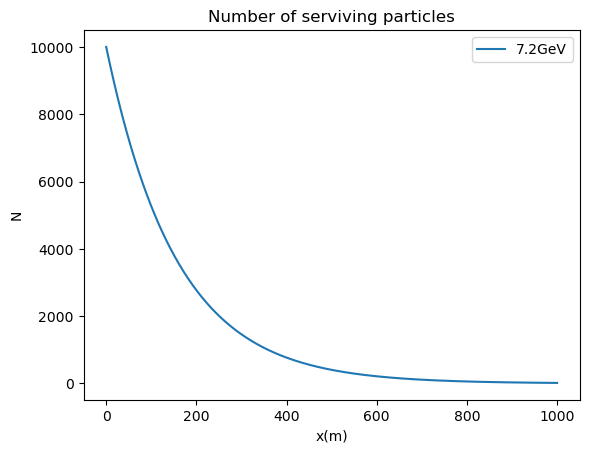

In [16]:
def servive_num(N,dx,tau,gamma):
    return N*np.exp(-dx/(scipy.constants.c*tau*np.sqrt(gamma**2-1)))

x = np.linspace(0,1000,1001)
dx = x[1]-x[0]
N_theory_servive = np.zeros(len(x))
N_theory_servive[0] = 10000
a = 0
for i in range(1,len(x)):
    N_theory_servive[i] = servive_num(N_theory_servive[i-1], 1, pion_life_time, 20)
    if N_theory_servive[0]>2*N_theory_servive[i] and a==0:
        print("approx half distance : "+str(x[i])+" m")
        a = 1

plt.title("Number of serviving particles")
plt.plot(x, N_theory_servive, label = '7.2GeV')
plt.xlabel("x(m)")
plt.ylabel("N")
plt.legend()

plt.show()

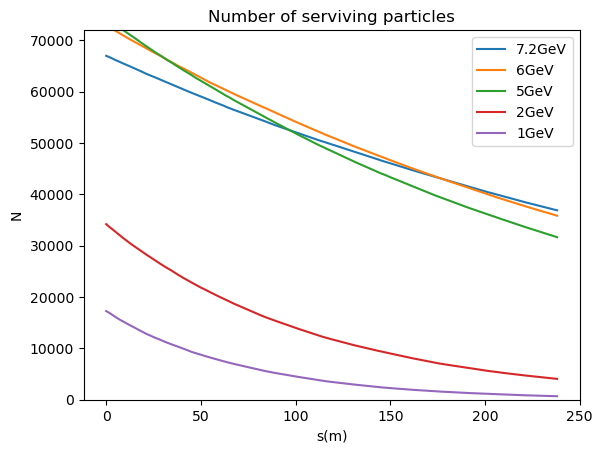

In [17]:
plt.title("Number of serviving particles")
plt.plot(s_lst[:131],N_lst_7GeV[:131], label = '7.2GeV')
plt.plot(s_lst[:131],N_lst_6GeV[:131], label = '6GeV')
plt.plot(s_lst[:131],N_lst_5GeV[:131], label = '5GeV')
plt.plot(s_lst[:131],N_lst_2GeV[:131], label = '2GeV')
plt.plot(s_lst[:131],N_lst_1GeV[:131], label = '1GeV')

plt.xlabel("s(m)")
plt.ylabel("N")
plt.ylim(0,72000)
plt.legend()

plt.show()

ratio of servival : 53.24328358208955 %
ratio of servival : 47.25240054869685 %
ratio of servival : 40.584947738936506 %
ratio of servival : 10.52046783625731 %
ratio of servival : 3.22524609148813 %


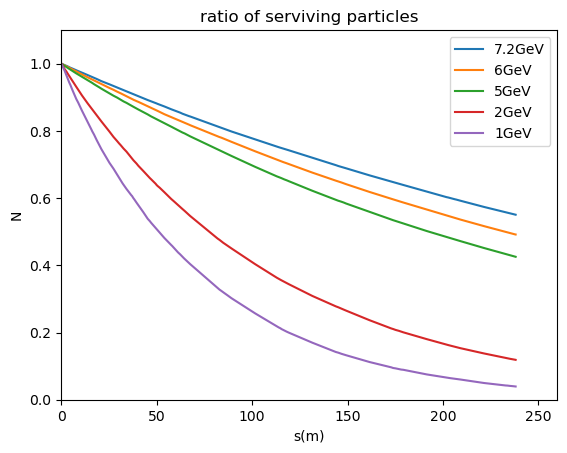

In [18]:
N_lst_lst = [N_lst_7GeV, N_lst_6GeV, N_lst_5GeV, N_lst_2GeV, N_lst_1GeV]
pion_E_lst = ["7GeV", "6GeV", "5GeV", "2GeV", "1GeV"]
for i in range(0, len(N_lst_lst)):
    print("ratio of servival : "+str(100*N_lst_lst[i][132]/N_lst_lst[i][0])+" %")

plt.title("ratio of serviving particles")

plt.plot(s_lst[:131],N_lst_7GeV[:131]/N_lst_7GeV[0], label = '7.2GeV')
plt.plot(s_lst[:131],N_lst_6GeV[:131]/N_lst_6GeV[0], label = '6GeV')
plt.plot(s_lst[:131],N_lst_5GeV[:131]/N_lst_5GeV[0], label = '5GeV')
plt.plot(s_lst[:131],N_lst_2GeV[:131]/N_lst_2GeV[0], label = '2GeV')
plt.plot(s_lst[:131],N_lst_1GeV[:131]/N_lst_1GeV[0], label = '1GeV')

plt.xlabel("s(m)")
plt.ylabel("N")
plt.xlim(0,260)
plt.ylim(0,1.1)
plt.legend()

plt.show()

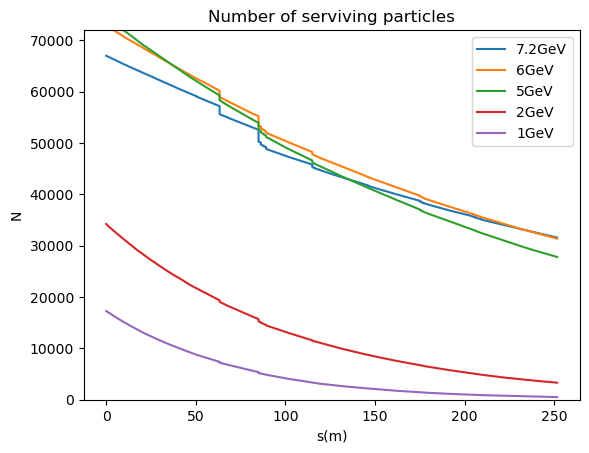

In [19]:
plt.title("Number of serviving particles")
plt.plot(s_lst_ap[:174],N_lst_7GeV_ap[:174], label = '7.2GeV')
plt.plot(s_lst_ap[:174],N_lst_6GeV_ap[:174], label = '6GeV')
plt.plot(s_lst_ap[:174],N_lst_5GeV_ap[:174], label = '5GeV')
plt.plot(s_lst_ap[:174],N_lst_2GeV_ap[:174], label = '2GeV')
plt.plot(s_lst_ap[:174],N_lst_1GeV_ap[:174], label = '1GeV')

plt.xlabel("s(m)")
plt.ylabel("N")
plt.ylim(0,72000)
plt.legend()

plt.show()

ratio of servival : 47.13774063572601 %
ratio of servival : 43.040943693848156 %
ratio of servival : 37.36061477281887 %
ratio of servival : 9.699661096178568 %
ratio of servival : 2.9520722389442002 %


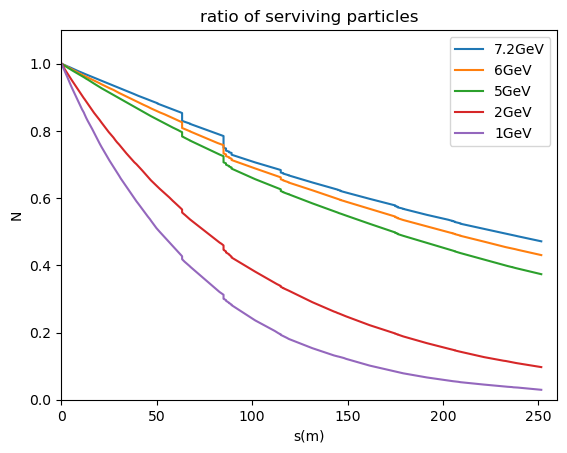

In [20]:
N_lst_lst = [N_lst_7GeV_ap, N_lst_6GeV_ap, N_lst_5GeV_ap, N_lst_2GeV_ap, N_lst_1GeV_ap]
pion_E_lst = ["7GeV", "6GeV", "5GeV", "2GeV", "1GeV"]
for i in range(0, len(N_lst_lst)):
    print("ratio of servival : "+str(100*N_lst_lst[i][173]/N_lst_lst[i][0])+" %")

plt.title("ratio of serviving particles")

plt.plot(s_lst_ap[:174],N_lst_7GeV_ap[:174]/N_lst_7GeV[0], label = '7.2GeV')
plt.plot(s_lst_ap[:174],N_lst_6GeV_ap[:174]/N_lst_6GeV[0], label = '6GeV')
plt.plot(s_lst_ap[:174],N_lst_5GeV_ap[:174]/N_lst_5GeV[0], label = '5GeV')
plt.plot(s_lst_ap[:174],N_lst_2GeV_ap[:174]/N_lst_2GeV[0], label = '2GeV')
plt.plot(s_lst_ap[:174],N_lst_1GeV_ap[:174]/N_lst_1GeV[0], label = '1GeV')

plt.xlabel("s(m)")
plt.ylabel("N")
plt.xlim(0,260)
plt.ylim(0,1.1)
plt.legend()

plt.show()

In [23]:
N_lst_5GeV_bdsim = np.array([74000, 73528, 73270, 73215, 72960, 72770, 72354, 71979, 71570, 71210, 70841, 70841, 70705, 70511, 
                          69995, 69959, 69567, 69351, 69112, 68988, 68589, 68028, 67628, 67628, 67171, 67171, 66966, 66760, 
                          66378, 66302, 65842, 65840, 65633, 65509, 64917, 64834, 64565, 64555, 64315, 64283, 64050, 63577, 
                          63381, 62963, 61914, 61469, 60530, 60443, 60562, 60625, 59915, 58898, 58672, 58554, 58363, 58363, 
                          57924, 57898, 57682, 57632, 56674, 56440, 55324, 55128, 54000, 53964, 53605, 50043, 49833, 49667, 
                          48153, 48152, 47709, 47699, 47027, 46954, 46037, 43373, 41635, 41480, 41319, 40750, 40750, 40483, 
                          40483, 40088, 40043, 39585, 37426, 36004, 35890, 35786, 34880, 34881, 34585, 34579, 34022, 33939, 
                          33337, 31378, 30243, 30138, 30036, 29808, 29810, 29669, 29667, 29431, 29413, 29120, 27841, 26820, 
                          26724, 26652, 26474, 26474, 26347, 26346, 26183, 26182, 26056, 24993, 24056, 23952, 23863, 23690, 
                          23690, 23579, 23579, 23425, 23425, 23318])

N_lst_5GeV_lin_opt_xyfix = np.array([74434.,73979.,73714.,73714.,73644.,73385.,73201.,72931.,72931.,72444.,
                                     72179.,72179.,71623.,71364.,71364.,71302.,71035.,70825.,70277.,70202.,
                                     69954.,69954.,69592.,69329.,69183.,68607.,68602.,67861.,67619.,67619.,
                                     67541.,67071.,67047.,66813.,66624.,66403.,66402.,66194.,65957.,65957.,
                                     65854.,65617.,65504.,64938.,64818.,64589.,64589.,64498.,64362.,64362.,
                                     64248.,64016.,63564.,63421.,63421.,62876.,61385.,61072.,60986.,60463.,
                                     60367.,60241.,60241.,60011.,59515.,58999.,58671.,58440.,58243.,58126.,
                                     58092.,57535.,55485.,55098.,53874.,53401.,52945.,52901.,52643.,51885.,
                                     51257.,48777.,48500.,48272.,45836.,44107.,43804.,43463.,42926.,42905.,
                                     42554.,41982.,41899.,41716.,41689.,41668.,41489.,41353.,39556.,38002.,
                                     37394.,37173.,36932.,36633.,36605.,36362.,36024.,35945.,35818.,35818.,
                                     35789.,35637.,35625.,34138.,32802.,32335.,32177.,32022.,31758.,31737.,
                                     31533.,31209.,31144.,31017.,31017.,30997.,30883.,30883.,29511.,28417.,
                                     28238.,28120.,27961.,27807.,27783.,27573.,27352.,27299.,27203.,27203.,
                                     27181.,27065.,27065.,25886.,24933.,24821.,24715.,24592.,24589.,24567.,
                                     24469.,24408.,24363.,24254.,24253.,24236.,24129.,24119.,23072.,22208.,
                                     22145.,22050.,21959.,21956.,21943.,21852.,21806.,21764.,21681.,21681.,
                                     21668.,21584.,21584.,20672.,    0.])

no ap : 40.584947738936506 % servived
with ap : 39.03055055485397 % servived
with ap : 31.510810810810813 % servived


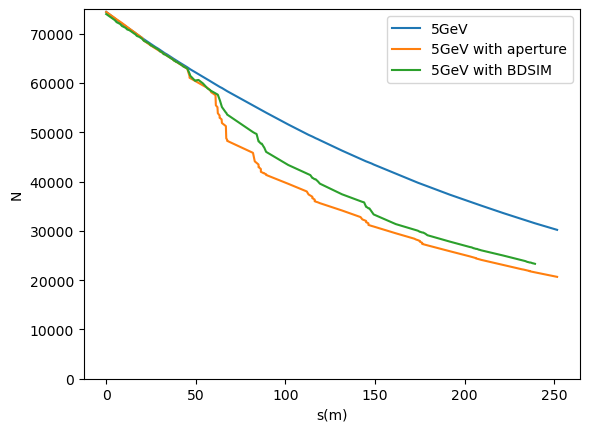

In [24]:
plt.plot(s_lst[:133],N_lst_5GeV[:133], label = '5GeV')
print("no ap : "+str(N_lst_5GeV[-3]/N_lst_5GeV[0]*100)+" % servived")
plt.plot(s_lst_ap[:174],N_lst_5GeV_lin_opt_xyfix[:174], label = '5GeV with aperture')
print("with ap : "+str(N_lst_5GeV_ap[-3]/N_lst_5GeV_ap[0]*100)+" % servived")
plt.plot(s_lst[:132],N_lst_5GeV_bdsim[:132], label = '5GeV with BDSIM')
print("with ap : "+str(N_lst_5GeV_bdsim[-1]/N_lst_5GeV_bdsim[0]*100)+" % servived")

plt.xlabel("s(m)")
plt.ylabel("N")
plt.ylim(0,75000)
plt.legend()

plt.show()

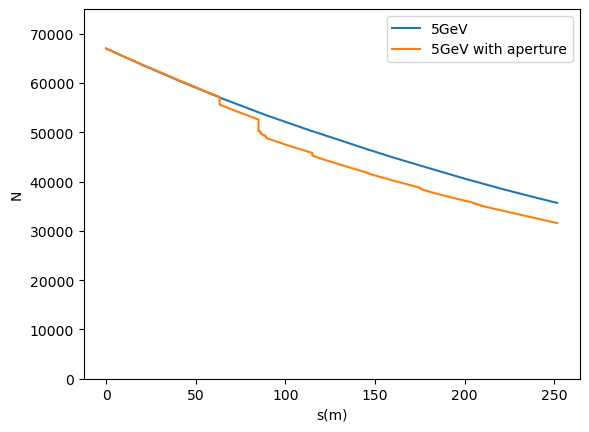

In [32]:
plt.plot(s_lst[:133],N_lst_7GeV[:133], label = '5GeV')
plt.plot(s_lst_ap[:174],N_lst_7GeV_ap[:174], label = '5GeV with aperture')

plt.xlabel("s(m)")
plt.ylabel("N")
plt.ylim(0,75000)
plt.legend()

plt.show()

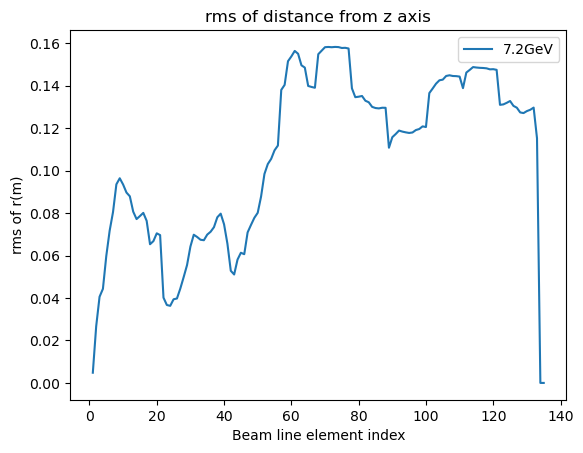

In [29]:
plt.title("rms of distance from z axis")
plt.plot(BL_index,r_lst_7GeV, label = '7.2GeV')
plt.xlabel("Beam line element index")
plt.ylabel("rms of r(m)")
plt.legend()

plt.show()

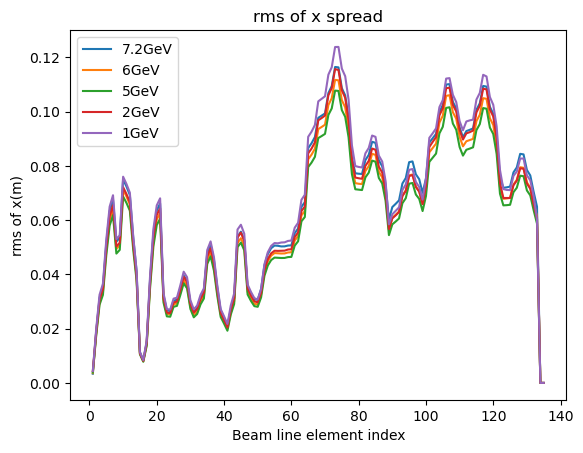

In [30]:
plt.title("rms of x spread")
plt.plot(BL_index,x_lst_7GeV, label = '7.2GeV')
plt.plot(BL_index,x_lst_6GeV, label = '6GeV')
plt.plot(BL_index,x_lst_5GeV, label = '5GeV')
plt.plot(BL_index,x_lst_2GeV, label = '2GeV')
plt.plot(BL_index,x_lst_1GeV, label = '1GeV')
plt.xlabel("Beam line element index")
plt.ylabel("rms of x(m)")
plt.legend()

plt.show()

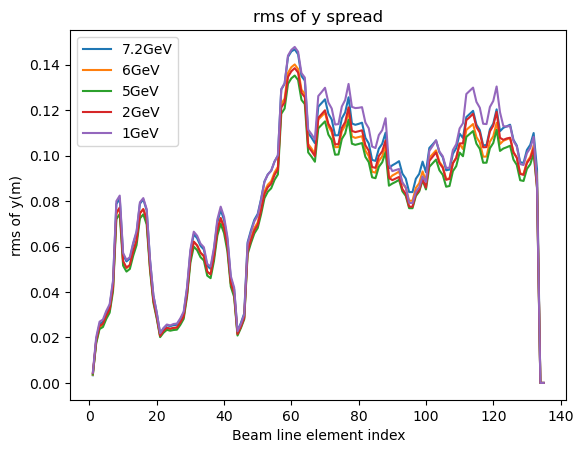

In [31]:
plt.title("rms of y spread")
plt.plot(BL_index,y_lst_7GeV, label = '7.2GeV')
plt.plot(BL_index,y_lst_6GeV, label = '6GeV')
plt.plot(BL_index,y_lst_5GeV, label = '5GeV')
plt.plot(BL_index,y_lst_2GeV, label = '2GeV')
plt.plot(BL_index,y_lst_1GeV, label = '1GeV')
plt.xlabel("Beam line element index")
plt.ylabel("rms of y(m)")
plt.legend()

plt.show()

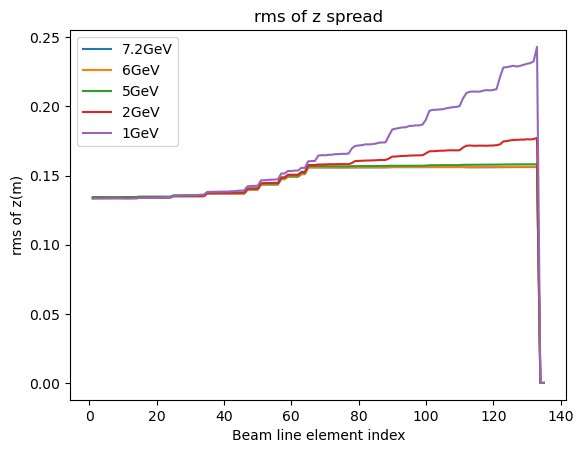

In [32]:
plt.title("rms of z spread")
plt.plot(BL_index,z_lst_7GeV, label = '7.2GeV')
plt.plot(BL_index,z_lst_6GeV, label = '6GeV')
plt.plot(BL_index,z_lst_5GeV, label = '5GeV')
plt.plot(BL_index,z_lst_2GeV, label = '2GeV')
plt.plot(BL_index,z_lst_1GeV, label = '1GeV')
plt.xlabel("Beam line element index")
plt.ylabel("rms of z(m)")
plt.legend()

plt.show()

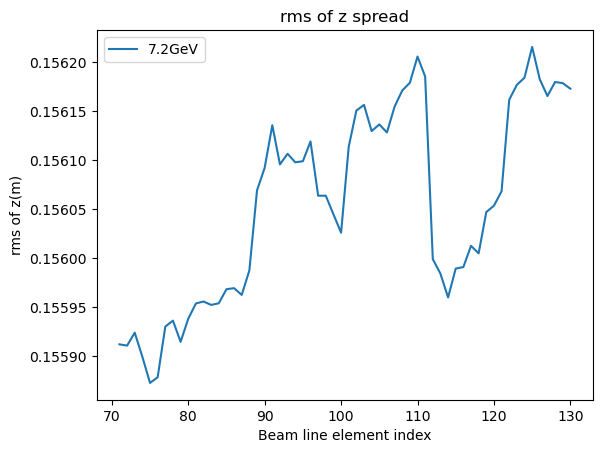

In [33]:
plt.title("rms of z spread")
plt.plot(BL_index[70:130],z_lst_7GeV[70:130], label = '7.2GeV')
plt.xlabel("Beam line element index")
plt.ylabel("rms of z(m)")
plt.legend()

plt.show()